In [86]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [87]:
# 한글 깨짐 방지 위해 구글 코랩에 나눔폰트 설치.
import sys
if 'google.colab' in sys.modules:
    !echo 'debconf debconf/frontend select Noninteractive' | debconf-set-selections
    !sudo apt-get -qq -y install fonts-nanum
    import matplotlib.font_manager as fm
    font_files = fm.findSystemFonts(fontpaths=['/usr/share/fonts/truetype/nanum'])
    for fpath in font_files:
        fm.fontManager.addfont(fpath)

In [88]:
# 필요한 라이브러리 설치 및 임포트
#!pip install pandas

import pandas as pd
import datetime
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [89]:
plt.rcParams['font.family'] = 'NanumGothic'
plt.rcParams['axes.unicode_minus'] = False

---

# [Step 2] 데이터 전처리

#### **<span style="color:blue">[2-0] air_21, air_22, weather_21, weather_22 데이터 로딩</span>**

In [90]:
# 데이터 로딩
air_21 = pd.read_csv('/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/(제공용) 미세먼지 교안, 데이터 및 실습 과제/air_2021.csv', index_col=0)
air_22 = pd.read_csv('/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/(제공용) 미세먼지 교안, 데이터 및 실습 과제/air_2022.csv', index_col=0)
weather_21 = pd.read_csv('/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/(제공용) 미세먼지 교안, 데이터 및 실습 과제/weather_2021.csv', sep=',', encoding='cp949')
weather_22 = pd.read_csv('/content/drive/MyDrive/AI+X/AI+X선도인재양성프로젝트(중급)/(제공용) 미세먼지 교안, 데이터 및 실습 과제/weather_2022.csv', sep=',', encoding='cp949')

#### **<span style="color:blue">[2-1] air_21, air_22 의 '측정일시'를 활용하여 'time' 변수 생성</span>**

* air_21, air_22 의 '측정일시'를 활용하여 'time'변수 생성
* time 변수를 to_datetime으로 데이터 타입 변경
* 참고: 미세먼지 데이터는 1시-24시, 날씨 데이터는 0시-23시로 구성되어 있습니다. [2-5]에서 미세먼지와 날씨 데이터를 time 기준으로 합치려면 날씨 기준이 동일해야 합니다. 미세먼지 데이터에서 time 변수 생성 시 이를 미리 고려(예:측정일시 값 -1)하세요.

In [91]:
air_21['time'] = air_21['측정일시'].astype(str)

# 자정은 다음날 00시여야 하는데 당일날 24시로 되어 있음...
temp = air_21['time'].str[-2:] == '24'


air_21.loc[temp, 'time'] = ( pd.to_datetime(air_21.loc[temp, 'time'].str.slice(0,8), format='%Y%m%d') + pd.Timedelta(days=1)).dt.strftime('%Y%m%d') + '00'

air_21['time'] = pd.to_datetime(air_21['time'], format='%Y%m%d%H')

In [92]:
air_22['time'] = air_22['측정일시'].astype(str)

# 자정은 다음날 00시여야 하는데 당일날 24시로 되어 있음...
temp = air_22['time'].str[-2:] == '24'


air_22.loc[temp, 'time'] = (pd.to_datetime(air_22.loc[temp, 'time'].str.slice(0,8), format='%Y%m%d') + pd.Timedelta(days=1)).dt.strftime('%Y%m%d') + '00'

air_22['time'] = pd.to_datetime(air_22['time'], format='%Y%m%d%H')

In [93]:
air_21.head()

,지역,망,측정소코드,측정소명,측정일시,SO2,CO,O3,NO2,PM10,PM25,주소,time
0,서울 종로구,도시대기,111123,종로구,2021100101,0.003,0.6,0.002,0.039,31.0,18.0,서울 종로구 종로35가길 19,2021-10-01 01:00:00
1,서울 종로구,도시대기,111123,종로구,2021100102,0.003,0.6,0.002,0.035,27.0,16.0,서울 종로구 종로35가길 19,2021-10-01 02:00:00
2,서울 종로구,도시대기,111123,종로구,2021100103,0.003,0.6,0.002,0.033,28.0,18.0,서울 종로구 종로35가길 19,2021-10-01 03:00:00
3,서울 종로구,도시대기,111123,종로구,2021100104,0.003,0.6,0.002,0.030,26.0,16.0,서울 종로구 종로35가길 19,2021-10-01 04:00:00
4,서울 종로구,도시대기,111123,종로구,2021100105,0.003,0.5,0.003,0.026,26.0,16.0,서울 종로구 종로35가길 19,2021-10-01 05:00:00


In [94]:
# 2022년 1월 1일 00시 데이터가 2021데이터에 있음.
air_21[air_21['time']=='2022-01-01 00:00:00']

,지역,망,측정소코드,측정소명,측정일시,SO2,CO,O3,NO2,PM10,PM25,주소,time
2207,서울 종로구,도시대기,111123,종로구,2021123124,0.003,0.4,0.026,0.016,20.0,9.0,서울 종로구 종로35가길 19,2022-01-01


In [95]:
# 2022년 1월 1일 00시 데이터가 2021데이터에 있음. -> 수정
air_22 = pd.concat([air_22, air_21[air_21['time']=='2022-01-01 00:00:00']], ignore_index=True)

---

#### **<span style="color:blue">[2-2] weather_21, weather_22 의 '일시'를 활용하여 'time' 변수 생성</span>**

* weather_21, weather_22 의 '일시'를 활용하여 'time'변수 생성
* time 변수를 to_datetime으로 데이터 타입 변경

In [96]:
weather_21['time'] = pd.to_datetime(weather_21['일시'])
weather_22['time'] = pd.to_datetime(weather_22['일시'])

---

#### **<span style="color:blue">[2-3] 'time' 기준으로 데이터 합치기</span>**

* 미세먼지 데이터와 날씨 데이터를 'time' 기준으로 합쳐보세요.
* df_21에는 'time' 기준으로 21년도 미세먼지, 날씨 데이터를 합쳐보세요.
* df_22에는 'time' 기준으로 22년도 미세먼지, 날씨 데이터를 합쳐보세요.

In [97]:
df_21 = pd.merge(air_21, weather_21, on='time', how='inner')
df_22 = pd.merge(air_22, weather_22, on='time', how='inner')

In [98]:
df_21.head()

,지역,망,측정소코드,측정소명,측정일시,SO2,CO,O3,NO2,PM10,...,최저운고(100m ),시정(10m),지면상태(지면상태코드),현상번호(국내식),지면온도(°C),지면온도 QC플래그,5cm 지중온도(°C),10cm 지중온도(°C),20cm 지중온도(°C),30cm 지중온도(°C)
0,서울 종로구,도시대기,111123,종로구,2021100101,0.003,0.6,0.002,0.039,31.0,...,NaN,2000,NaN,NaN,17.4,NaN,22.1,22.0,22.5,22.9
1,서울 종로구,도시대기,111123,종로구,2021100102,0.003,0.6,0.002,0.035,27.0,...,NaN,2000,NaN,NaN,17.2,NaN,21.8,21.8,22.4,22.8
2,서울 종로구,도시대기,111123,종로구,2021100103,0.003,0.6,0.002,0.033,28.0,...,NaN,2000,NaN,NaN,17.0,NaN,21.6,21.6,22.2,22.8
3,서울 종로구,도시대기,111123,종로구,2021100104,0.003,0.6,0.002,0.030,26.0,...,NaN,2000,NaN,NaN,16.5,NaN,21.3,21.4,22.0,22.7
4,서울 종로구,도시대기,111123,종로구,2021100105,0.003,0.5,0.003,0.026,26.0,...,NaN,1995,NaN,NaN,16.6,NaN,21.1,21.2,21.9,22.6


In [99]:
df_22.head()

,지역,망,측정소코드,측정소명,측정일시,SO2,CO,O3,NO2,PM10,...,최저운고(100m ),시정(10m),지면상태(지면상태코드),현상번호(국내식),지면온도(°C),지면온도 QC플래그,5cm 지중온도(°C),10cm 지중온도(°C),20cm 지중온도(°C),30cm 지중온도(°C)
0,서울 종로구,도시대기,111123,종로구,2022010101,0.003,0.4,0.026,0.016,23.0,...,NaN,2000,NaN,NaN,-7.2,NaN,-1.1,-1.1,-0.2,1.0
1,서울 종로구,도시대기,111123,종로구,2022010102,0.003,0.4,0.022,0.020,20.0,...,NaN,2000,NaN,NaN,-7.5,NaN,-1.3,-1.2,-0.2,1.0
2,서울 종로구,도시대기,111123,종로구,2022010103,0.003,0.5,0.014,0.028,20.0,...,NaN,2000,NaN,NaN,-7.6,NaN,-1.4,-1.2,-0.2,1.0
3,서울 종로구,도시대기,111123,종로구,2022010104,0.003,0.5,0.016,0.027,19.0,...,NaN,2000,NaN,NaN,-7.6,NaN,-1.4,-1.3,-0.3,1.0
4,서울 종로구,도시대기,111123,종로구,2022010105,0.003,0.5,0.005,0.040,24.0,...,NaN,2000,NaN,NaN,-7.7,NaN,-1.5,-1.4,-0.3,1.0


---

#### **<span style="color:blue">[2-4] 사용하지 않을 변수 제거</span>**

* 머신러닝에 사용하지 않을 변수들을 제거해줍니다.
* df_21, df_22에 사용할 변수들만 넣어보세요.

In [100]:
df_21.columns

Index(['지역', '망', '측정소코드', '측정소명', '측정일시', 'SO2', 'CO', 'O3', 'NO2', 'PM10',
       'PM25', '주소', 'time', '지점', '지점명', '일시', '기온(°C)', '기온 QC플래그',
       '강수량(mm)', '강수량 QC플래그', '풍속(m/s)', '풍속 QC플래그', '풍향(16방위)', '풍향 QC플래그',
       '습도(%)', '습도 QC플래그', '증기압(hPa)', '이슬점온도(°C)', '현지기압(hPa)', '현지기압 QC플래그',
       '해면기압(hPa)', '해면기압 QC플래그', '일조(hr)', '일조 QC플래그', '일사(MJ/m2)',
       '일사 QC플래그', '적설(cm)', '3시간신적설(cm)', '전운량(10분위)', '중하층운량(10분위)',
       '운형(운형약어)', '최저운고(100m )', '시정(10m)', '지면상태(지면상태코드)', '현상번호(국내식)',
       '지면온도(°C)', '지면온도 QC플래그', '5cm 지중온도(°C)', '10cm 지중온도(°C)',
       '20cm 지중온도(°C)', '30cm 지중온도(°C)'],
      dtype='object')

In [101]:
df_22.columns

Index(['지역', '망', '측정소코드', '측정소명', '측정일시', 'SO2', 'CO', 'O3', 'NO2', 'PM10',
       'PM25', '주소', 'time', '지점', '지점명', '일시', '기온(°C)', '기온 QC플래그',
       '강수량(mm)', '강수량 QC플래그', '풍속(m/s)', '풍속 QC플래그', '풍향(16방위)', '풍향 QC플래그',
       '습도(%)', '습도 QC플래그', '증기압(hPa)', '이슬점온도(°C)', '현지기압(hPa)', '현지기압 QC플래그',
       '해면기압(hPa)', '해면기압 QC플래그', '일조(hr)', '일조 QC플래그', '일사(MJ/m2)',
       '일사 QC플래그', '적설(cm)', '3시간신적설(cm)', '전운량(10분위)', '중하층운량(10분위)',
       '운형(운형약어)', '최저운고(100m )', '시정(10m)', '지면상태(지면상태코드)', '현상번호(국내식)',
       '지면온도(°C)', '지면온도 QC플래그', '5cm 지중온도(°C)', '10cm 지중온도(°C)',
       '20cm 지중온도(°C)', '30cm 지중온도(°C)'],
      dtype='object')

In [102]:
df_21.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8759 entries, 0 to 8758
Data columns (total 51 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   지역             8759 non-null   object        
 1   망              8759 non-null   object        
 2   측정소코드          8759 non-null   int64         
 3   측정소명           8759 non-null   object        
 4   측정일시           8759 non-null   int64         
 5   SO2            8647 non-null   float64       
 6   CO             8679 non-null   float64       
 7   O3             8662 non-null   float64       
 8   NO2            8679 non-null   float64       
 9   PM10           8654 non-null   float64       
 10  PM25           8662 non-null   float64       
 11  주소             8759 non-null   object        
 12  time           8759 non-null   datetime64[ns]
 13  지점             8759 non-null   int64         
 14  지점명            8759 non-null   object        
 15  일시             8759 n

In [103]:
# df_21, df_22에 사용할 변수들만 할당
df_21.drop(['망', '측정소코드', '측정소명', '측정일시', '주소', '지점', '지점명', '일시', '기온 QC플래그','강수량 QC플래그', '풍속 QC플래그', '풍향 QC플래그', '습도 QC플래그', '현지기압 QC플래그', '해면기압 QC플래그', '일조 QC플래그', '일사 QC플래그', '지면상태(지면상태코드)', '현상번호(국내식)', '지면온도 QC플래그', '운형(운형약어)'], axis=1, inplace=True)
df_22.drop(['망', '측정소코드', '측정소명', '측정일시', '주소', '지점', '지점명', '일시', '기온 QC플래그','강수량 QC플래그', '풍속 QC플래그', '풍향 QC플래그', '습도 QC플래그', '현지기압 QC플래그', '해면기압 QC플래그', '일조 QC플래그', '일사 QC플래그', '지면상태(지면상태코드)', '현상번호(국내식)', '지면온도 QC플래그', '운형(운형약어)'], axis=1, inplace=True)

In [104]:
# time 변수를 index로 세팅
df_21 = df_21.set_index('time')
df_22 = df_22.set_index('time')

df_21 = df_21.sort_index()
df_22 = df_22.sort_index()

###############################################

In [105]:
# df_21, df_22에 사용할 변수들만 할당
temp_21 = df_21.copy()
temp_22 = df_22.copy()

In [106]:
temp_21.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 8759 entries, 2021-01-01 01:00:00 to 2021-12-31 23:00:00
Data columns (total 29 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   지역             8759 non-null   object 
 1   SO2            8647 non-null   float64
 2   CO             8679 non-null   float64
 3   O3             8662 non-null   float64
 4   NO2            8679 non-null   float64
 5   PM10           8654 non-null   float64
 6   PM25           8662 non-null   float64
 7   기온(°C)         8759 non-null   float64
 8   강수량(mm)        949 non-null    float64
 9   풍속(m/s)        8757 non-null   float64
 10  풍향(16방위)       8757 non-null   float64
 11  습도(%)          8759 non-null   int64  
 12  증기압(hPa)       8759 non-null   float64
 13  이슬점온도(°C)      8759 non-null   float64
 14  현지기압(hPa)      8759 non-null   float64
 15  해면기압(hPa)      8759 non-null   float64
 16  일조(hr)         4791 non-null   float64
 17  일사(MJ/m2)      4

In [107]:
temp_21.isna().sum()

,0
지역,0
SO2,112
CO,80
O3,97
NO2,80
PM10,105
PM25,97
기온(°C),0
강수량(mm),7810
풍속(m/s),2


In [108]:
temp_21.columns

Index(['지역', 'SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25', '기온(°C)', '강수량(mm)',
       '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)', '현지기압(hPa)',
       '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '3시간신적설(cm)', '전운량(10분위)',
       '중하층운량(10분위)', '최저운고(100m )', '시정(10m)', '지면온도(°C)', '5cm 지중온도(°C)',
       '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)'],
      dtype='object')

In [109]:
tmp = temp_21[['PM10', 'PM25', '강수량(mm)', '적설(cm)', '3시간신적설(cm)', '일조(hr)', '일사(MJ/m2)']].fillna(0)
tmp.head()

,PM10,PM25,강수량(mm),적설(cm),3시간신적설(cm),일조(hr),일사(MJ/m2)
time,,,,,,,
2021-01-01 01:00:00,24.0,14.0,0.0,0.0,0.0,0.0,0.0
2021-01-01 02:00:00,25.0,14.0,0.0,0.0,0.0,0.0,0.0
2021-01-01 03:00:00,27.0,16.0,0.0,0.0,0.0,0.0,0.0
2021-01-01 04:00:00,23.0,13.0,0.0,0.0,0.0,0.0,0.0
2021-01-01 05:00:00,24.0,14.0,0.0,0.0,0.0,0.0,0.0


In [110]:
tmp.corr()

,PM10,PM25,강수량(mm),적설(cm),3시간신적설(cm),일조(hr),일사(MJ/m2)
PM10,1.000000,0.677440,-0.044660,0.006048,-0.001556,0.032114,0.015729
PM25,0.677440,1.000000,-0.055592,0.035191,0.009324,-0.023623,-0.051306
강수량(mm),-0.044660,-0.055592,1.000000,-0.002284,0.050563,-0.070884,-0.060868
적설(cm),0.006048,0.035191,-0.002284,1.000000,0.270726,-0.016234,-0.049264
3시간신적설(cm),-0.001556,0.009324,0.050563,0.270726,1.000000,-0.017963,-0.016219
일조(hr),0.032114,-0.023623,-0.070884,-0.016234,-0.017963,1.000000,0.820351
일사(MJ/m2),0.015729,-0.051306,-0.060868,-0.049264,-0.016219,0.820351,1.000000


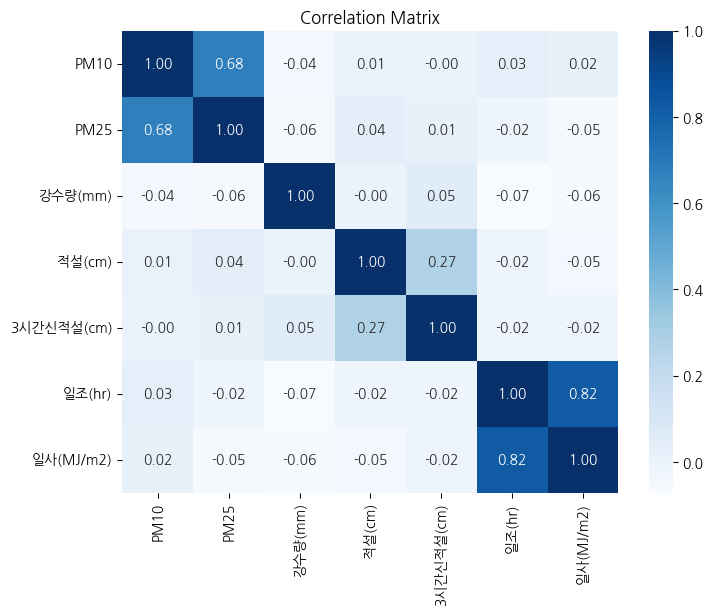

In [111]:
plt.figure(figsize=(8, 6))
sns.heatmap(tmp.corr(), annot=True, cmap='Blues', fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

####################################

In [112]:
# df_21.to_csv('df_21.csv', encoding='utf-8-sig')

In [113]:
# df_22.to_csv('df_22.csv', encoding='utf-8-sig')

---

#### **<span style="color:blue">[2-5] 변수들의 결측치 처리</span>**

In [114]:
# df_21의 결측치 확인
df_21.isna().sum()

,0
지역,0
SO2,112
CO,80
O3,97
NO2,80
PM10,105
PM25,97
기온(°C),0
강수량(mm),7810
풍속(m/s),2


In [115]:
# df_22의 결측치 확인
df_22.isna().sum()

,0
지역,0
SO2,21
CO,21
O3,21
NO2,21
PM10,38
PM25,25
기온(°C),0
강수량(mm),2079
풍속(m/s),0


In [116]:
df_21.columns

Index(['지역', 'SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25', '기온(°C)', '강수량(mm)',
       '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)', '현지기압(hPa)',
       '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '3시간신적설(cm)', '전운량(10분위)',
       '중하층운량(10분위)', '최저운고(100m )', '시정(10m)', '지면온도(°C)', '5cm 지중온도(°C)',
       '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)'],
      dtype='object')

##### '강수량(mm)'의 결측치를 처리

In [117]:
# df_21, df_22의 변수 중 '강수량(mm)'의 결측치를 처리
# 0.0mm운 강수량 측정 최소단위인 0.1mm 미만을 의미. 공란은 무강수를 의미 -> NaN값을 0으로 채움.
df_21['강수량(mm)'] = df_21['강수량(mm)'].fillna(0)
df_22['강수량(mm)'] = df_22['강수량(mm)'].fillna(0)

##### df_21, df_22의 남은 결측치를 처리

###### 결측치가 많은 변수부터 처리

In [118]:
# 일단 먼저 결측치가 많은 변수부터 처리

# 결측치는 측정기기 고장 등의 이슈 때문에 측정이 안된 거일 수도 있긴 함.
# 적설, 3시간신적설(cm) - 미세먼지와 거의 무상관 + 결측치가 많음. -> 일단 0으로 처리는 하긴 하지만 나중에 그냥 변수 전체 제거를 고려할 수도 있음.
# 일조와 일사는 데이터 파일을 조사한 결과 -> 일몰 이후부터 일출 이전까지는 NaN값 -> 0으로 처리해도 될 듯.
# 최저운고는 값이 작을 수록 지면과 구름이 가깝다는 것을 의미. 값이 있는 부분을 조사한 결과 -> 전운량, 중하층운량과 주로 반비례 양상.
# -> NaN값 부분은 주로 전운량과 중하층운량이 0 -> 그래서 최대한 터무니없는 값을 넣어서 구름이 지면과 매우 멀리 떨어져있다는 것을 표현.
# 혹시 전운량과 중하층운량을 사용해서 최저 운고를 예측할 수 있는 모델을 만들어서 NaN값을 채운다면..? -> 괜찮을까..?
# 최저운고는 전운량, 중하층운량과 밀접한 상관관계가 있을 수도 있음 -> 다중공선성 문제가 있다면 삭제할 수도 있음.

df_21['적설(cm)'] = df_21['적설(cm)'].fillna(0)
df_21['3시간신적설(cm)'] = df_21['3시간신적설(cm)'].fillna(0)

df_21['일조(hr)'] = df_21['일조(hr)'].fillna(0)
df_21['일사(MJ/m2)'] = df_21['일사(MJ/m2)'].fillna(0)

df_21['최저운고(100m )'] = df_21['최저운고(100m )'].fillna(0)  # 0으로 교체



df_21[['일조(hr)', '일사(MJ/m2)', '적설(cm)', '3시간신적설(cm)', '최저운고(100m )', 'PM10', 'PM25', '강수량(mm)']].corr()

,일조(hr),일사(MJ/m2),적설(cm),3시간신적설(cm),최저운고(100m ),PM10,PM25,강수량(mm)
일조(hr),1.000000,0.820351,-0.016234,-0.017963,-0.134158,0.037861,-0.015925,-0.070884
일사(MJ/m2),0.820351,1.000000,-0.049264,-0.016219,-0.042131,0.023099,-0.041389,-0.060868
적설(cm),-0.016234,-0.049264,1.000000,0.270726,-0.041075,0.006794,0.035976,-0.002284
3시간신적설(cm),-0.017963,-0.016219,0.270726,1.000000,-0.008973,-0.001309,0.009846,0.050563
최저운고(100m ),-0.134158,-0.042131,-0.041075,-0.008973,1.000000,-0.059441,-0.033641,-0.030430
PM10,0.037861,0.023099,0.006794,-0.001309,-0.059441,1.000000,0.674708,-0.044364
PM25,-0.015925,-0.041389,0.035976,0.009846,-0.033641,0.674708,1.000000,-0.055710
강수량(mm),-0.070884,-0.060868,-0.002284,0.050563,-0.030430,-0.044364,-0.055710,1.000000


In [119]:
df_22['적설(cm)'] = df_22['적설(cm)'].fillna(0)
df_22['3시간신적설(cm)'] = df_22['3시간신적설(cm)'].fillna(0)

df_22['일조(hr)'] = df_22['일조(hr)'].fillna(0)
df_22['일사(MJ/m2)'] = df_22['일사(MJ/m2)'].fillna(0)

df_22['최저운고(100m )'] = df_22['최저운고(100m )'].fillna(0) # 0으로 교체

###### 결측치가 적은 변수 처리

In [120]:
# 전운량(10분위)

# df_21[df_21['전운량(10분위)'].isna()]
# df_21.loc['2021-08-14 17:00:00':'2021-08-14 21:00:00', ['전운량(10분위)', '중하층운량(10분위)']]

# 한 시간마다 전운량이 측정되므로 "선형보간"으로 값을 채움.
df_21['전운량(10분위)'] = df_21['전운량(10분위)'].interpolate(method='linear')

In [121]:
# 풍속(m/s)

#df_21[df_21['풍속(m/s)'].isna()]
# df_21.loc['2021-01-07 7:00:00':'2021-01-07 15:00:00', ['풍속(m/s)', '풍향(16방위)']]

# 이날은 풍속이 결측치 주변의 관측값들이 전반적으로 4~5였음. "선형보간"으로 값을 채움.
# 물론 풍속은 매번 갑작스럽게 바뀌지만....ㅎ
df_21['풍속(m/s)'] = df_21['풍속(m/s)'].interpolate(method='linear')

In [122]:
# 풍향(16방위)

#df_21[df_21['풍향(16방위)'].isna()]
#df_21.loc['2021-01-07 7:00:00':'2021-01-07 15:00:00', ['풍향(16방위)']]

# NaN값 이전과 이후를 살펴보면 풍향이 270에서 290으로 변화했음. "선형보간"으로 값을 채움.
# 16방위 이므로 270과 290사이에는 데이터 특성상 값이 있으면 안될 듯..
# NaN값이 연속해서 있으므로 하나는 270, 다른 하나는 290으로 채움.
df_21.loc['2021-01-07 11:00:00', '풍향(16방위)'] = 270.0
df_21.loc['2021-01-07 12:00:00', '풍향(16방위)'] = 290.0

In [123]:
# 지면온도(°C), 5cm 지중온도(°C), 10cm 지중온도(°C), 20cm 지중온도(°C), 30cm 지중온도(°C)

# 모두 같은 시간대에 NaN값이 있음 -> 기기 오류나 점검 등의 이유로 인한 결측값일 확률이 높음.

ground_temp = ['지면온도(°C)', '5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)']

# df_21[df_21['5cm 지중온도(°C)'].isna()]
#df_21.loc['2021-06-11 17:00:00':'2021-06-12 05:00:00', ground_temp]

# NaN값 주변을 보면, 온도가 시간이 지날수록 내려가고 있음. -> 선형 보간
df_21[ground_temp] = df_21[ground_temp].interpolate(method='linear')

In [124]:
df_21.loc['2021-06-11 17:00:00':'2021-06-12 05:00:00', ground_temp]

,지면온도(°C),5cm 지중온도(°C),10cm 지중온도(°C),20cm 지중온도(°C),30cm 지중온도(°C)
time,,,,,
2021-06-11 17:00:00,26.6,25.300000,24.1,23.1,22.7
2021-06-11 18:00:00,25.3,25.400000,24.3,23.2,22.7
2021-06-11 19:00:00,23.7,25.300000,24.3,23.3,22.8
2021-06-11 20:00:00,22.2,24.900000,24.2,23.4,22.8
2021-06-11 21:00:00,21.7,24.533333,23.9,23.3,22.8
2021-06-11 22:00:00,21.2,24.166667,23.6,23.2,22.8
2021-06-11 23:00:00,20.7,23.800000,23.3,23.1,22.8
2021-06-12 00:00:00,20.2,23.433333,23.0,23.0,22.8
2021-06-12 01:00:00,19.7,23.066667,22.7,22.9,22.8


In [125]:
# 대기 환경 데이터
# SO2, CO, O3, NO2, PM10, PM25
# NaN값은 특정일에 몇시간 동안 분포해있음. -> "에어코리아" > "고객지원" > "측정기 점검 알림" 공지사항을 찾아본 결과 대기환경측정소 측정기 점검으로 인해 NaN값이 있는 것으로 예상됨.

air_cols = ['SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25']

#df_21[df_21['PM10'].isna()].index
#df_21.loc['2021-01-05 10:00:00':'2021-01-05 15:00:00', air_cols]

# NaN값 주변을 보면, 대기 농도가 시간이 지날수록 올라가거나 내려가고 있음. -> 선형 보간
df_21[air_cols] = df_21[air_cols].interpolate(method='linear')

# 미세먼지 농도는 소수부분이 없으므로 반올림
df_21['PM10'] = df_21['PM10'].round()
df_21['PM25'] = df_21['PM25'].round()

In [126]:
df_21.loc['2021-01-05 10:00:00':'2021-01-05 15:00:00', air_cols]

,SO2,CO,O3,NO2,PM10,PM25
time,,,,,,
2021-01-05 10:00:00,0.004,0.5,0.020000,0.021000,36.0,19.0
2021-01-05 11:00:00,0.003,0.4,0.028000,0.016000,35.0,22.0
2021-01-05 12:00:00,0.003,0.4,0.029667,0.014667,33.0,19.0
2021-01-05 13:00:00,0.003,0.4,0.031333,0.013333,32.0,15.0
2021-01-05 14:00:00,0.003,0.4,0.033000,0.012000,30.0,12.0
2021-01-05 15:00:00,0.003,0.4,0.031000,0.016000,25.0,12.0


In [127]:
df_22[air_cols] = df_22[air_cols].interpolate(method='linear')

df_22['PM10'] = df_22['PM10'].round()
df_22['PM25'] = df_22['PM25'].round()

In [128]:
# df_21, df_22의 결측치 재확인
df_21.isna().sum()

,0
지역,0
SO2,0
CO,0
O3,0
NO2,0
PM10,0
PM25,0
기온(°C),0
강수량(mm),0
풍속(m/s),0


In [129]:
df_22.isna().sum()

,0
지역,0
SO2,0
CO,0
O3,0
NO2,0
PM10,0
PM25,0
기온(°C),0
강수량(mm),0
풍속(m/s),0


In [130]:
df_21.to_csv('df_21.csv', encoding='utf-8-sig')
df_22.to_csv('df_22.csv', encoding='utf-8-sig')

---

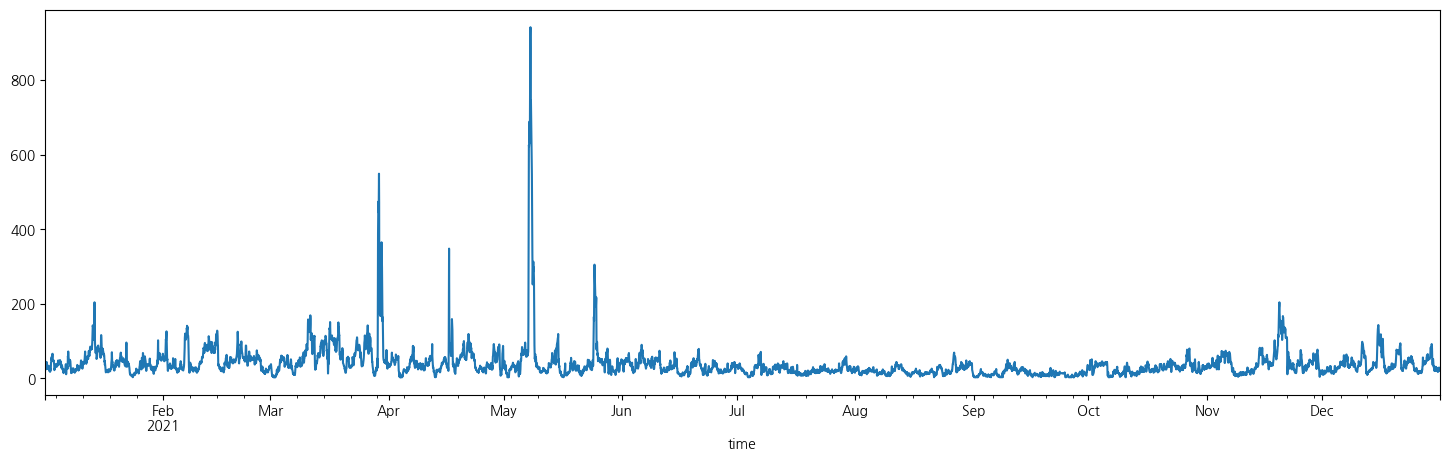

In [131]:
# 결측치 처리 후 그래프 확인 하고 싶으면 해보등가
from matplotlib import dates
df_21['PM10'].plot(figsize=(18,5)).autoscale(axis='x', tight=True)

주요 주기 성분 (상위 10개, 진폭 기준 정렬):
- 주파수: 0.000000 Hz | 진폭: 86664.33 | 주기: 8759.00 시간 ≈ 364.96 일
- 주파수: 0.000001 Hz | 진폭: 44304.68 | 주기: 437.95 시간 ≈ 18.25 일
- 주파수: 0.000001 Hz | 진폭: 40905.44 | 주기: 336.88 시간 ≈ 14.04 일
- 주파수: 0.000002 Hz | 진폭: 40493.27 | 주기: 182.48 시간 ≈ 7.60 일
- 주파수: 0.000001 Hz | 진폭: 39537.38 | 주기: 461.00 시간 ≈ 19.21 일
- 주파수: 0.000000 Hz | 진폭: 35181.78 | 주기: 673.77 시간 ≈ 28.07 일
- 주파수: 0.000001 Hz | 진폭: 34312.20 | 주기: 224.59 시간 ≈ 9.36 일
- 주파수: 0.000000 Hz | 진폭: 34069.42 | 주기: 4379.50 시간 ≈ 182.48 일
- 주파수: 0.000002 Hz | 진폭: 33711.84 | 주기: 153.67 시간 ≈ 6.40 일
- 주파수: 0.000000 Hz | 진폭: 32742.99 | 주기: 973.22 시간 ≈ 40.55 일


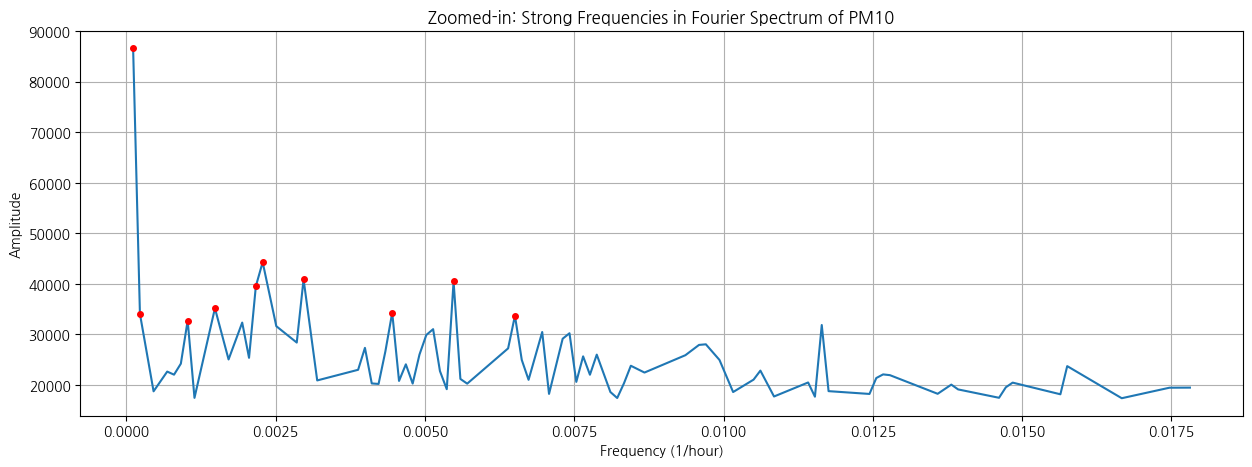

In [132]:
# 2. 분석 대상 열 선택
col = 'PM10'  # 원하는 컬럼명으로 변경
signal = df_21[col].dropna()  # 이산 신호

# 3. 푸리에 변환
N = len(signal) # 샘플 개수
dt = 3600  # 1시간 단위 = 3600초  1시간단위로 샘플링
fft_result = np.fft.fft(signal) # DTFT
freqs = np.fft.fftfreq(N, d=dt) # 주파수 벡터 생성
amplitude = np.abs(fft_result) # 진폭을 보기 위해 절댓값을 취함.

# 4. 양의 주파수만 추출
mask = freqs > 0
positive_freqs = freqs[mask]
positive_amplitude = amplitude[mask]

# 5. 상위 주파수 성분 추출
N_top = 10
top_idx = np.argsort(positive_amplitude)[-N_top:]
dominant_freqs = positive_freqs[top_idx]
dominant_amplitudes = positive_amplitude[top_idx]

# 6. 주기 계산
dominant_periods_sec = 1 / dominant_freqs
dominant_periods_hours = dominant_periods_sec / 3600
dominant_periods_days = dominant_periods_hours / 24

# 데이터프레임으로 만들어서 정렬(주기 기준으로 정렬)
import pandas as pd

dominant_df = pd.DataFrame({
    'Frequency (Hz)': dominant_freqs,
    'Amplitude': dominant_amplitudes,
    'Period (hours)': dominant_periods_hours,
    'Period (days)': dominant_periods_days
})

# 원하는 기준으로 정렬 (ex: 진폭 기준으로 내림차순)
dominant_df = dominant_df.sort_values(by='Amplitude', ascending=False)

# 7. 결과 출력
print("주요 주기 성분 (상위 {}개, 진폭 기준 정렬):".format(N_top))
for idx, row in dominant_df.iterrows():
    print(f"- 주파수: {row['Frequency (Hz)']:.6f} Hz | 진폭: {row['Amplitude']:.2f} | 주기: {row['Period (hours)']:.2f} 시간 ≈ {row['Period (days)']:.2f} 일")

# 8. 스펙트럼 시각화
threshold = positive_amplitude.max() * 0.2
mask = positive_amplitude > threshold

plt.figure(figsize=(15, 5))
plt.plot((positive_freqs[mask]) * 3600, positive_amplitude[mask])  # 주파수를 1/hour 단위로
plt.plot(dominant_freqs * 3600, dominant_amplitudes, 'o', color='red', label='Top Frequencies', markersize=4)
plt.title(f'Zoomed-in: Strong Frequencies in Fourier Spectrum of {col}')
plt.xlabel('Frequency (1/hour)')
plt.ylabel('Amplitude')
plt.grid(True)
plt.show()

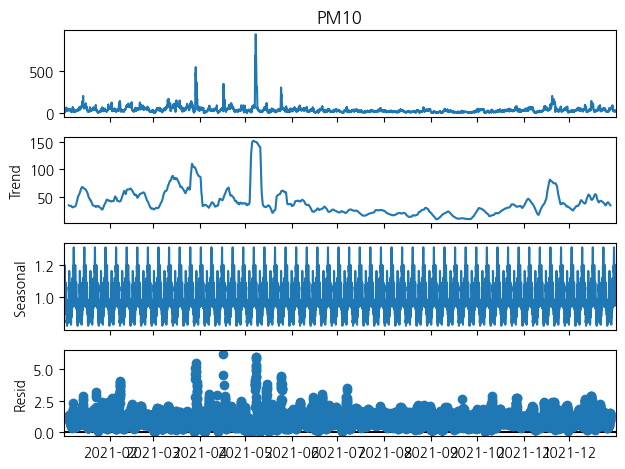

In [133]:
from statsmodels.tsa.seasonal import seasonal_decompose
result = seasonal_decompose(df_21['PM10'], model='mul', period=168)  # 7일 -> 168 = 24hx7일
result.plot();

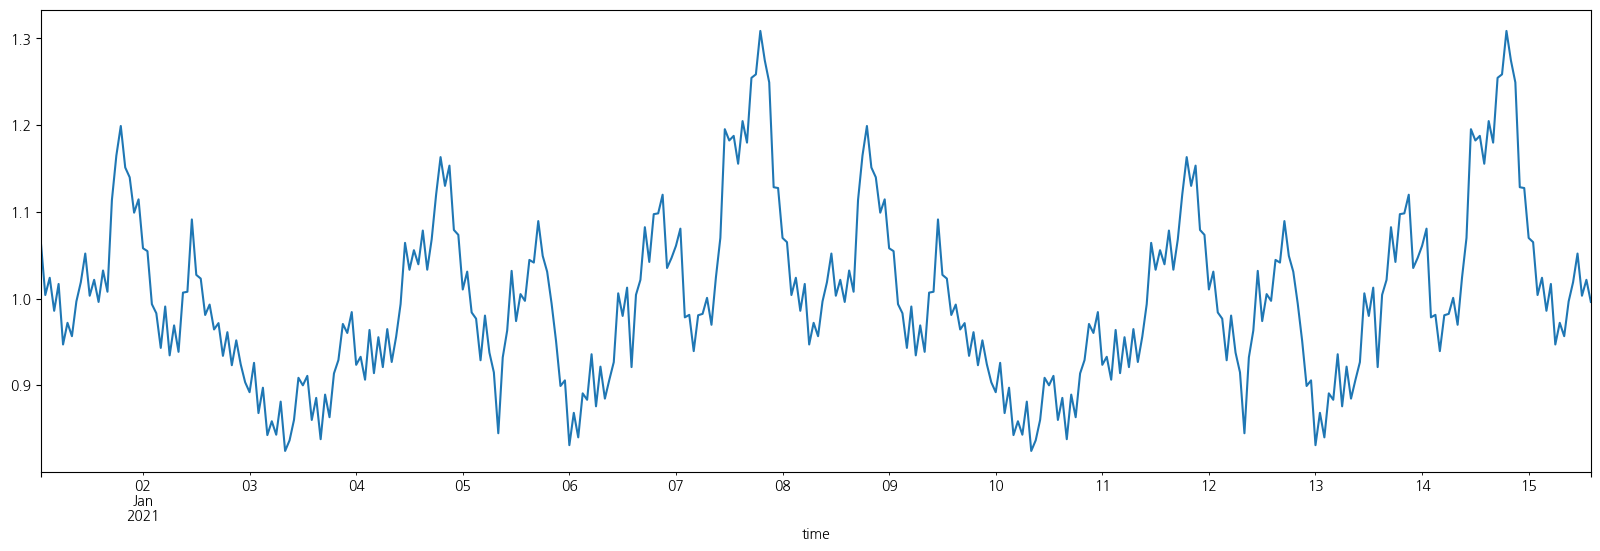

In [134]:
result.seasonal.iloc[:350].plot(figsize=(20,6));

#### **<span style="color:blue">[2-6] 전일 같은 시간 변수 추가</span>**

* 모델링에 유용한 변수로 전일 같은 시간(24시간 전) 미세먼지 농도 변수를 추가합니다.
* 시계열 데이터 처리를 위한 shift 연산을 참고하세요.

In [135]:
# df_21, df_22의 index(time)를 month, day, hour 로 쪼개기 (year는 필요 없음)
df_21['month'] = df_21.index.month
df_21['day']   = df_21.index.day
df_21['hour']  = df_21.index.hour

df_22['month'] = df_22.index.month
df_22['day']   = df_22.index.day
df_22['hour']  = df_22.index.hour

In [136]:
df_21.head(3)

,지역,SO2,CO,O3,NO2,PM10,PM25,기온(°C),강수량(mm),풍속(m/s),...,최저운고(100m ),시정(10m),지면온도(°C),5cm 지중온도(°C),10cm 지중온도(°C),20cm 지중온도(°C),30cm 지중온도(°C),month,day,hour
time,,,,,,,,,,,,,,,,,,,,,
2021-01-01 01:00:00,서울 종로구,0.002,0.5,0.022,0.016,24.0,14.0,-8.7,0.0,2.4,...,0.0,2000,-6.9,-1.0,-0.8,0.3,1.6,1,1,1
2021-01-01 02:00:00,서울 종로구,0.002,0.6,0.018,0.020,25.0,14.0,-9.1,0.0,1.6,...,0.0,2000,-7.1,-1.1,-0.8,0.3,1.6,1,1,2
2021-01-01 03:00:00,서울 종로구,0.002,0.6,0.013,0.025,27.0,16.0,-9.3,0.0,1.1,...,0.0,2000,-7.3,-1.2,-0.9,0.3,1.6,1,1,3


In [137]:
# df_21, df_22에 전일 같은 시간 미세먼지 농도 변수(PM10_lag1) 추가 (하루 전)
# 전일 같은 시간은 24시간 전 입니다.
df_21['PM10_lag1'] = df_21['PM10'].shift(24) # df_21['PM10']의 24시간 전 데이터

df_22['PM10_lag1'] = df_22['PM10'].shift(24)

In [138]:
# df_21[['PM10', 'PM10_lag1']].head(30)

---

#### **<span style="color:blue">[2-7] t+1 시점의 미세먼지 농도 데이터 생성</span>**

* t+1 시점은 1시간 후 입니다.
* t+1 시점의 미세먼지 농도 변수를 생성하세요.
* t+1 시점의 미세먼지 농도는 머신러닝 모델을 통해 예측하려는 y값(target) 입니다.

In [139]:
# df_21, df_22에 t+1 시점(다음날) 변수(PM10_1) 추가
df_21['PM10_1']= df_21['PM10'].shift(-1)

df_22['PM10_1']= df_22['PM10'].shift(-1)

In [140]:
#df_21[['PM10', 'PM10_lag1', 'PM10_1']].head(30)

In [141]:
# 결측치가 있다면 처리
# shift연산을 했으므로 당연히 결측치가 생김. 일단 냅두자

In [143]:
df_21.to_csv('df_21.csv', encoding='utf-8-sig')
df_22.to_csv('df_22.csv', encoding='utf-8-sig')

---

#### **<span style="color:blue">[2-8] train, test 데이터 분리 및 저장</span>**

* 회귀모델의 데이터 셋 만들기
  - y1 : PM10_1 (t+1 시점의 미세먼지 농도)
  - x1 : time , PM10, PM10_lag1 컬럼을 제외한 나머지 컬럼

* 시계열모델의 데이터 셋 만들기
  - y2 : PM10_1 (t+1 시점의 미세먼지 농도)
  - x2 : time 컬럼을 제외한 모든 컬럼들 (과거의 PM10, PM10_lag1 활용하여 PM10_1 예측 수행)

* train 데이터는 2021년 데이터 사용
* test 데이터는 2022년 데이터 사용


In [57]:
# 아래에 필요한 코드를 작성하고 결과를 확인합니다.(회귀모델의 데이터 셋 만들기)

df_21.reset_index(inplace=True)
df_22.reset_index(inplace=True)

train_x1 = df_21.drop(['PM10_1', 'time' , 'PM10', 'PM10_lag1'], axis=1)
train_y1 = df_21['PM10_1']
test_x1 = df_22.drop(['PM10_1', 'time' , 'PM10', 'PM10_lag1'], axis=1)
test_y1 = df_22['PM10_1']

In [58]:
# 각각의 데이터프레임을 csv 파일로 저장 (train_x1.csv / train_y1.csv / test_x1.csv / test_y1.csv)

train_x1.to_csv('train_x1.csv', index = False)
train_y1.to_csv('train_y1.csv', index = False)
test_x1.to_csv('test_x1.csv', index = False)
test_y1.to_csv('test_y1.csv', index = False)

In [59]:
# 아래에 필요한 코드를 작성하고 결과를 확인합니다.(시계열모델의 데이터 셋 만들기)

train_x2 = df_21.drop(['PM10_1', 'time'], axis=1)
train_y2 = df_21['PM10_1']
test_x2 = df_22.drop(['PM10_1', 'time'], axis=1)
test_y2 = df_22['PM10_1']

In [60]:
# 각각의 데이터프레임을 csv 파일로 저장 (train_x2.csv / train_y2.csv / test_x2.csv / test_y2.csv)

train_x2.to_csv('train_x2.csv', index = False)
train_y2.to_csv('train_y2.csv', index = False)
test_x2.to_csv('test_x2.csv', index = False)
test_y2.to_csv('test_y2.csv', index = False)

## [2-9] 결측치 처리 이후의 데이터 분석

In [61]:
air_21 = df_21[['time', 'SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25']].set_index('time')

In [62]:
air_22 = df_22[['time', 'SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25']].set_index('time')

In [63]:
weather_21 = df_21[['time', '기온(°C)','강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
                    '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '3시간신적설(cm)',
                    '전운량(10분위)', '중하층운량(10분위)', '최저운고(100m )', '시정(10m)', '지면온도(°C)',
                    '5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)']].set_index('time')

In [64]:
weather_22 = df_22[['time', '기온(°C)','강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
                    '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '3시간신적설(cm)',
                    '전운량(10분위)', '중하층운량(10분위)', '최저운고(100m )', '시정(10m)', '지면온도(°C)',
                    '5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)']].set_index('time')

### air_21

In [65]:
air_21.describe()

,SO2,CO,O3,NO2,PM10,PM25
count,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000
mean,0.003382,0.505109,0.029323,0.023277,38.786277,20.400046
std,0.000825,0.208962,0.019690,0.014432,47.250765,16.511348
min,0.001000,0.200000,0.000000,0.003000,3.000000,1.000000
25%,0.003000,0.400000,0.015000,0.012000,18.000000,10.000000
50%,0.003000,0.400000,0.028000,0.019000,30.000000,16.000000
75%,0.004000,0.600000,0.040000,0.031000,46.000000,25.000000
max,0.011000,2.000000,0.137000,0.082000,942.000000,154.000000


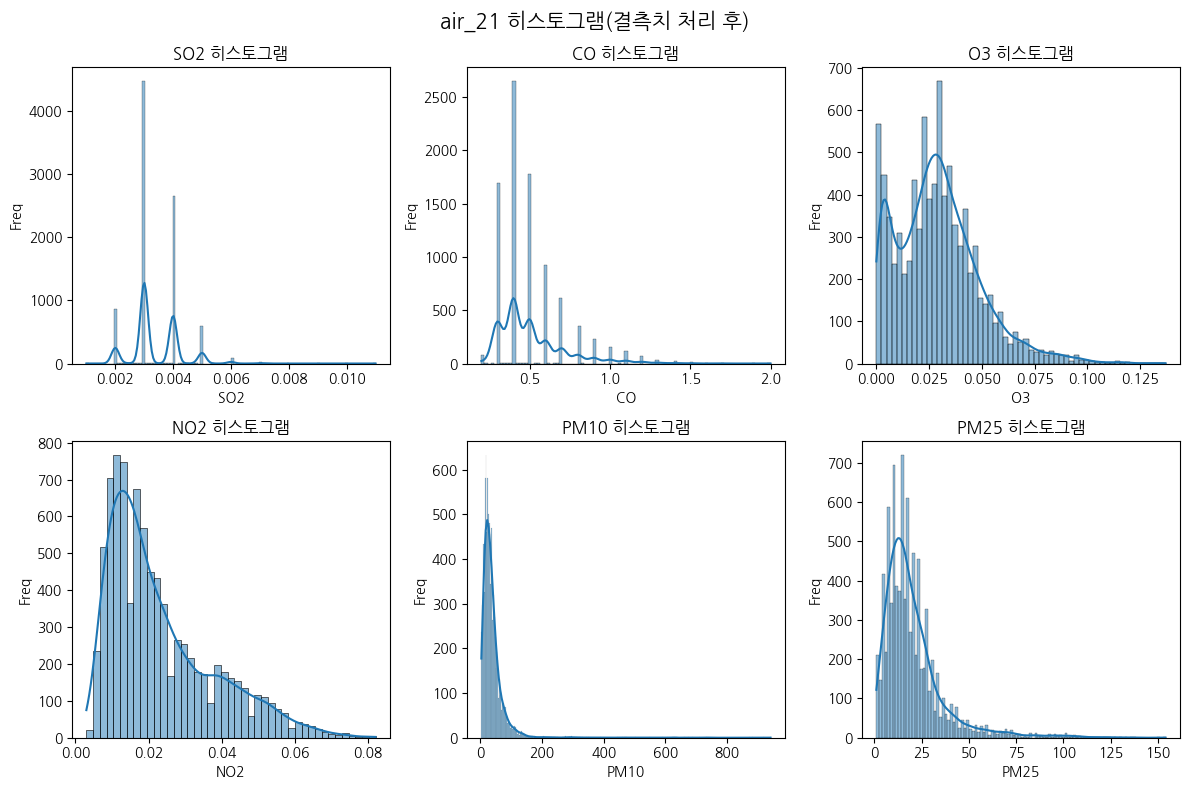

In [66]:
# air_21 히스토그램
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
cols = ['SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25']
idx = 0
for r in range(2):
    for c in range(3):
        sns.histplot(data=air_21, x=cols[idx], kde=True, ax=axes[r, c])
        axes[r, c].set_xlabel(cols[idx])
        axes[r, c].set_ylabel('Freq')
        axes[r, c].set_title(f'{cols[idx]} 히스토그램')
        idx += 1
fig.suptitle('air_21 히스토그램(결측치 처리 후)', fontsize=15)
plt.tight_layout()
plt.show()

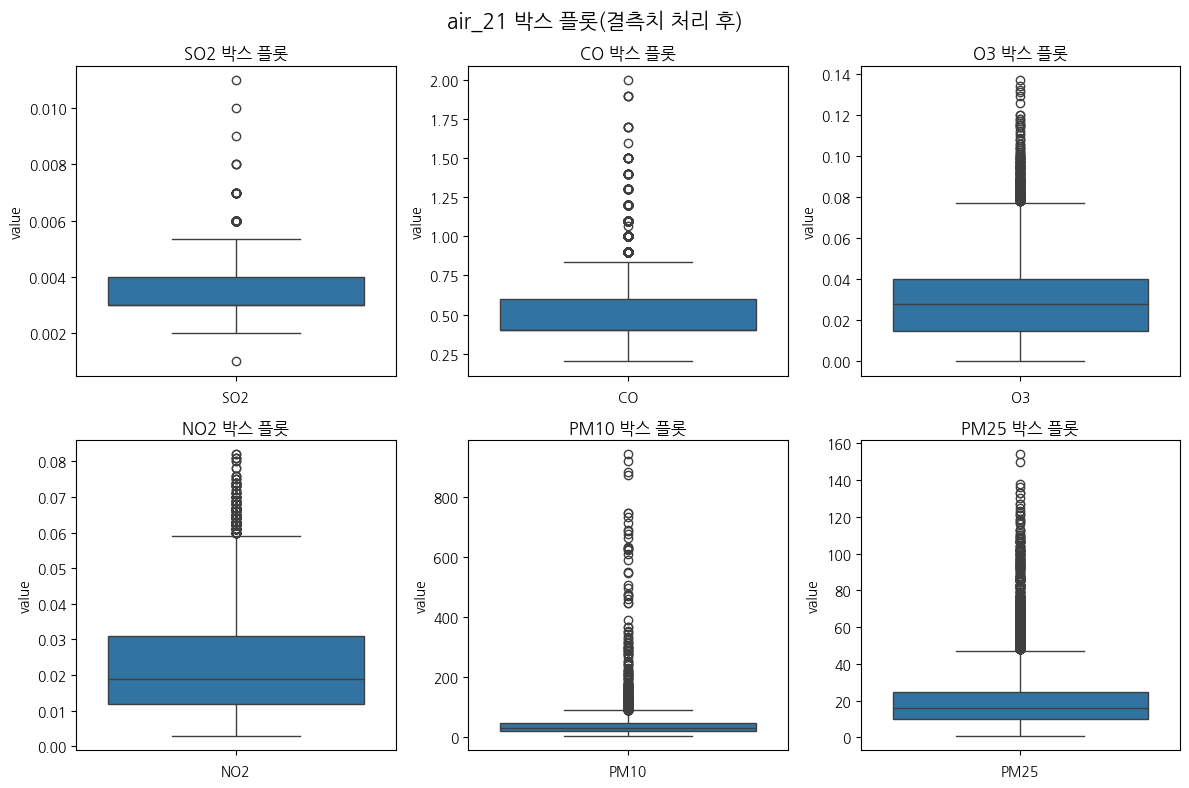

In [67]:
# air_21 박스 플롯
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
cols = ['SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25']
idx = 0
for r in range(2):
    for c in range(3):
        sns.boxplot(data=air_21, y=cols[idx], ax=axes[r, c])
        axes[r, c].set_xlabel(cols[idx])
        axes[r, c].set_ylabel('value')
        axes[r, c].set_title(f'{cols[idx]} 박스 플롯')
        idx += 1
fig.suptitle('air_21 박스 플롯(결측치 처리 후)', fontsize=15)
plt.tight_layout()
plt.show()

In [68]:
# air_21의 변수간의 상관관계 확인
air_21_corr = air_21[['SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25']].corr()
air_21_corr

,SO2,CO,O3,NO2,PM10,PM25
SO2,1.000000,0.339758,0.107594,0.330694,0.219093,0.380848
CO,0.339758,1.000000,-0.463350,0.866803,0.312285,0.639472
O3,0.107594,-0.463350,1.000000,-0.578584,-0.027966,-0.086959
NO2,0.330694,0.866803,-0.578584,1.000000,0.243388,0.518927
PM10,0.219093,0.312285,-0.027966,0.243388,1.000000,0.675412
PM25,0.380848,0.639472,-0.086959,0.518927,0.675412,1.000000


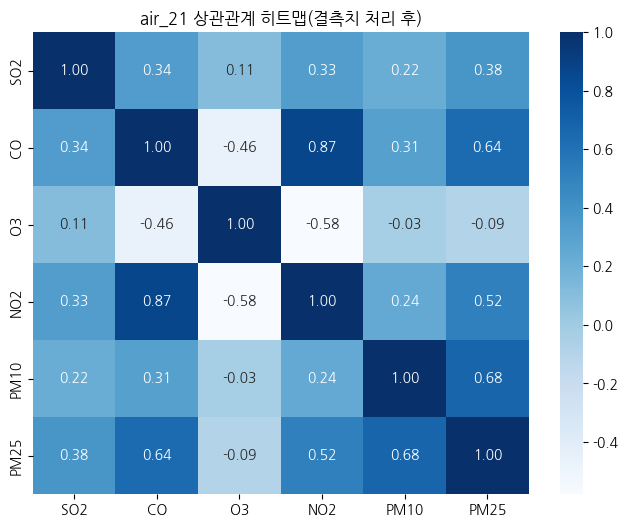

In [69]:
# air_21의 변수간의 상관관계를 히트맵으로 시각화
plt.figure(figsize=(8, 6))
sns.heatmap(air_21_corr, annot=True, cmap='Blues', fmt=".2f")
plt.title("air_21 상관관계 히트맵(결측치 처리 후)")
plt.show()

### air_22

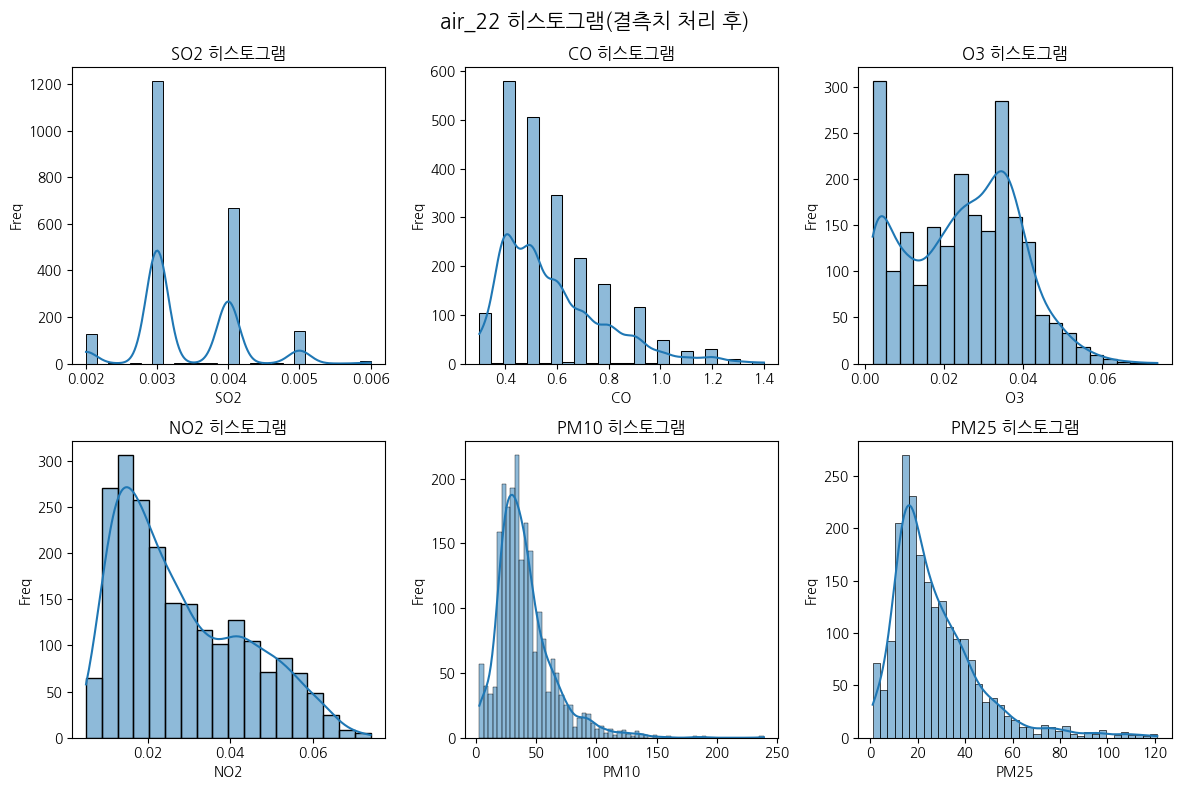

In [70]:
# air_22 히스토그램
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
cols = ['SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25']
idx = 0
for r in range(2):
    for c in range(3):
        sns.histplot(data=air_22, x=cols[idx], kde=True, ax=axes[r, c])
        axes[r, c].set_xlabel(cols[idx])
        axes[r, c].set_ylabel('Freq')
        axes[r, c].set_title(f'{cols[idx]} 히스토그램')
        idx += 1
fig.suptitle('air_22 히스토그램(결측치 처리 후)', fontsize=15)
plt.tight_layout()
plt.show()

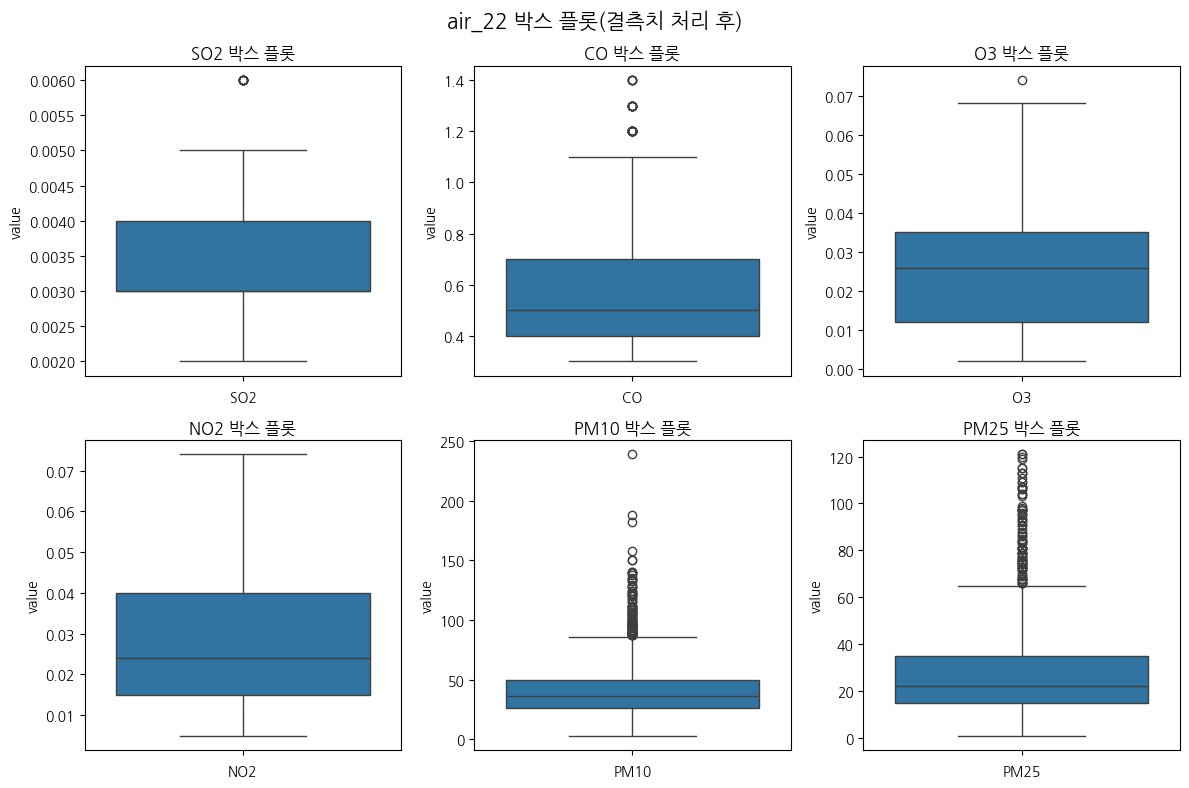

In [71]:
# air_22 박스 플롯
fig, axes = plt.subplots(2, 3, figsize=(12, 8))
cols = ['SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25']
idx = 0
for r in range(2):
    for c in range(3):
        sns.boxplot(data=air_22, y=cols[idx], ax=axes[r, c])
        axes[r, c].set_xlabel(cols[idx])
        axes[r, c].set_ylabel('value')
        axes[r, c].set_title(f'{cols[idx]} 박스 플롯')
        idx += 1
fig.suptitle('air_22 박스 플롯(결측치 처리 후)', fontsize=15)
plt.tight_layout()
plt.show()

In [72]:
# air_22의 변수간의 상관관계 확인
air_22_corr = air_22[['SO2', 'CO', 'O3', 'NO2', 'PM10', 'PM25']].corr()
air_22_corr

,SO2,CO,O3,NO2,PM10,PM25
SO2,1.000000,0.468570,-0.232592,0.449580,0.340936,0.353180
CO,0.468570,1.000000,-0.663433,0.827912,0.510452,0.662191
O3,-0.232592,-0.663433,1.000000,-0.796118,-0.053431,-0.184249
NO2,0.449580,0.827912,-0.796118,1.000000,0.319434,0.407604
PM10,0.340936,0.510452,-0.053431,0.319434,1.000000,0.864565
PM25,0.353180,0.662191,-0.184249,0.407604,0.864565,1.000000


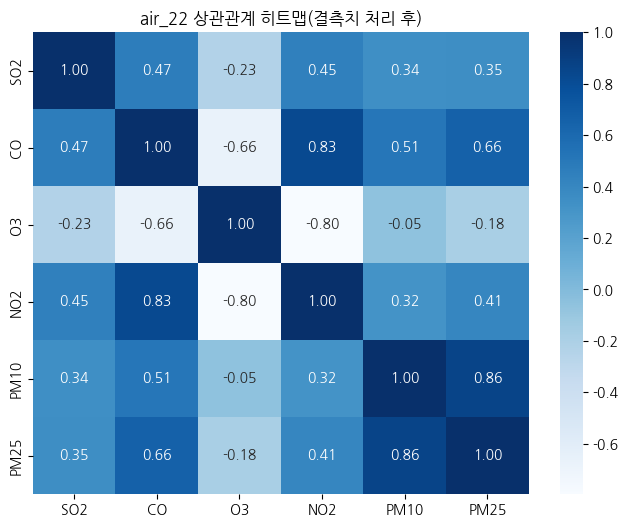

In [73]:
# air_22의 변수간의 상관관계를 히트맵으로 시각화
plt.figure(figsize=(8, 6))
sns.heatmap(air_22_corr, annot=True, cmap='Blues', fmt=".2f")
plt.title("air_22 상관관계 히트맵(결측치 처리 후)")
plt.show()

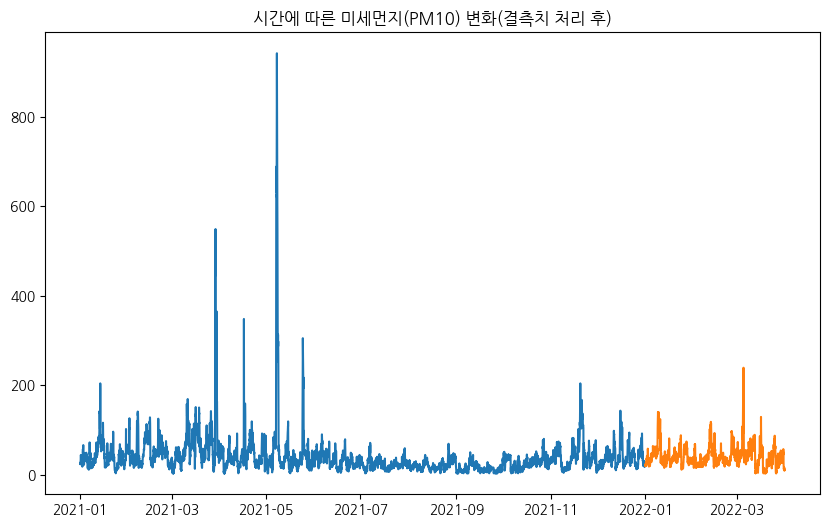

In [74]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(air_21['PM10'])
ax.plot(air_22['PM10'])
ax.set_title('시간에 따른 미세먼지(PM10) 변화(결측치 처리 후)')
plt.show()

### weather_21

In [75]:
weather_21[['기온(°C)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
            '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)','전운량(10분위)',
            '최저운고(100m )', '지면온도(°C)', '5cm 지중온도(°C)']].describe()

,기온(°C),풍속(m/s),풍향(16방위),습도(%),증기압(hPa),이슬점온도(°C),현지기압(hPa),해면기압(hPa),일조(hr),일사(MJ/m2),전운량(10분위),최저운고(100m ),지면온도(°C),5cm 지중온도(°C)
count,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000,8759.000000
mean,13.739194,2.311896,169.683754,65.589223,12.631236,6.842094,1006.046603,1016.280317,0.250725,0.588937,4.960669,7.870647,14.737710,15.133531
std,10.894786,1.121412,107.550433,18.394276,8.282075,11.736897,7.928167,8.311602,0.396703,0.893383,3.928914,12.349983,12.039483,10.174793
min,-18.500000,0.000000,0.000000,19.000000,0.700000,-27.000000,986.900000,996.500000,0.000000,0.000000,0.000000,0.000000,-12.700000,-4.700000
25%,6.000000,1.500000,50.000000,51.000000,5.900000,-0.400000,999.800000,1009.700000,0.000000,0.000000,0.000000,0.000000,4.300000,5.950000
50%,14.600000,2.200000,200.000000,66.000000,9.700000,6.600000,1006.300000,1016.400000,0.000000,0.030000,6.000000,2.000000,15.500000,15.400000
75%,22.600000,2.900000,270.000000,80.000000,19.900000,17.400000,1012.000000,1022.500000,0.500000,0.930000,9.000000,10.000000,23.600000,24.100000
max,36.300000,8.300000,360.000000,100.000000,32.200000,25.300000,1025.800000,1037.400000,1.000000,3.740000,10.000000,76.000000,56.800000,35.700000


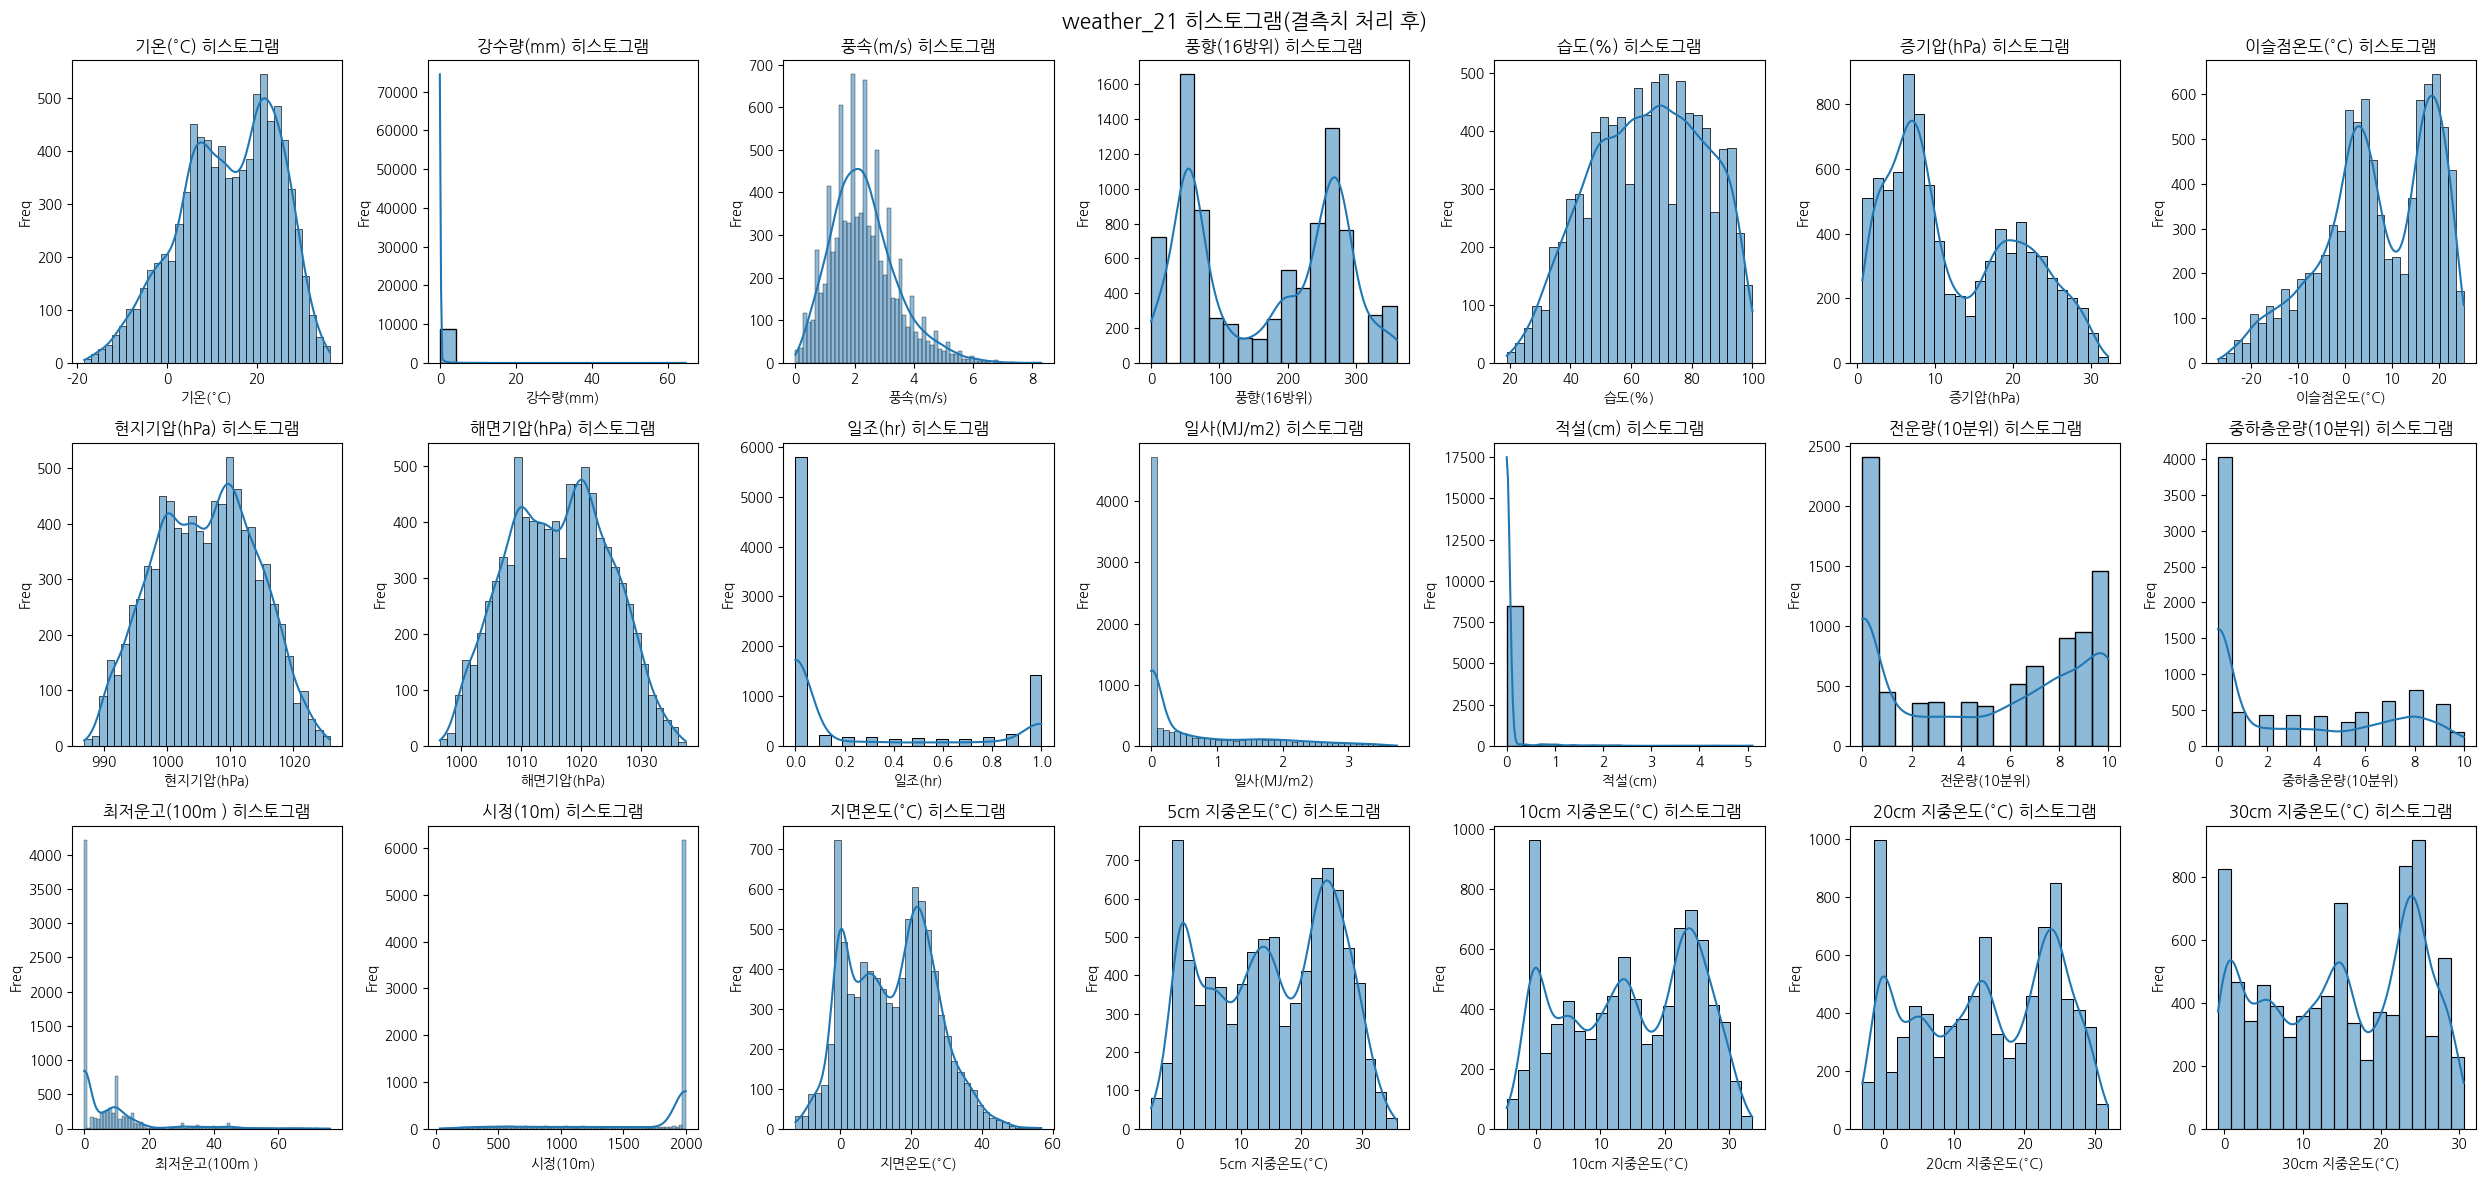

In [76]:
# weather_21 히스토그램
fig, axes = plt.subplots(3, 7, figsize=(25, 12))
cols = ['기온(°C)', '강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
        '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '전운량(10분위)', '중하층운량(10분위)',
        '최저운고(100m )', '시정(10m)', '지면온도(°C)', '5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)']
idx = 0
for r in range(3):
    for c in range(7):
        sns.histplot(data=weather_21, x=cols[idx], kde=True, ax=axes[r, c])
        axes[r, c].set_xlabel(cols[idx])
        axes[r, c].set_ylabel('Freq')
        axes[r, c].set_title(f'{cols[idx]} 히스토그램')
        idx += 1
fig.suptitle('weather_21 히스토그램(결측치 처리 후)', fontsize=15)
plt.tight_layout()
plt.show()

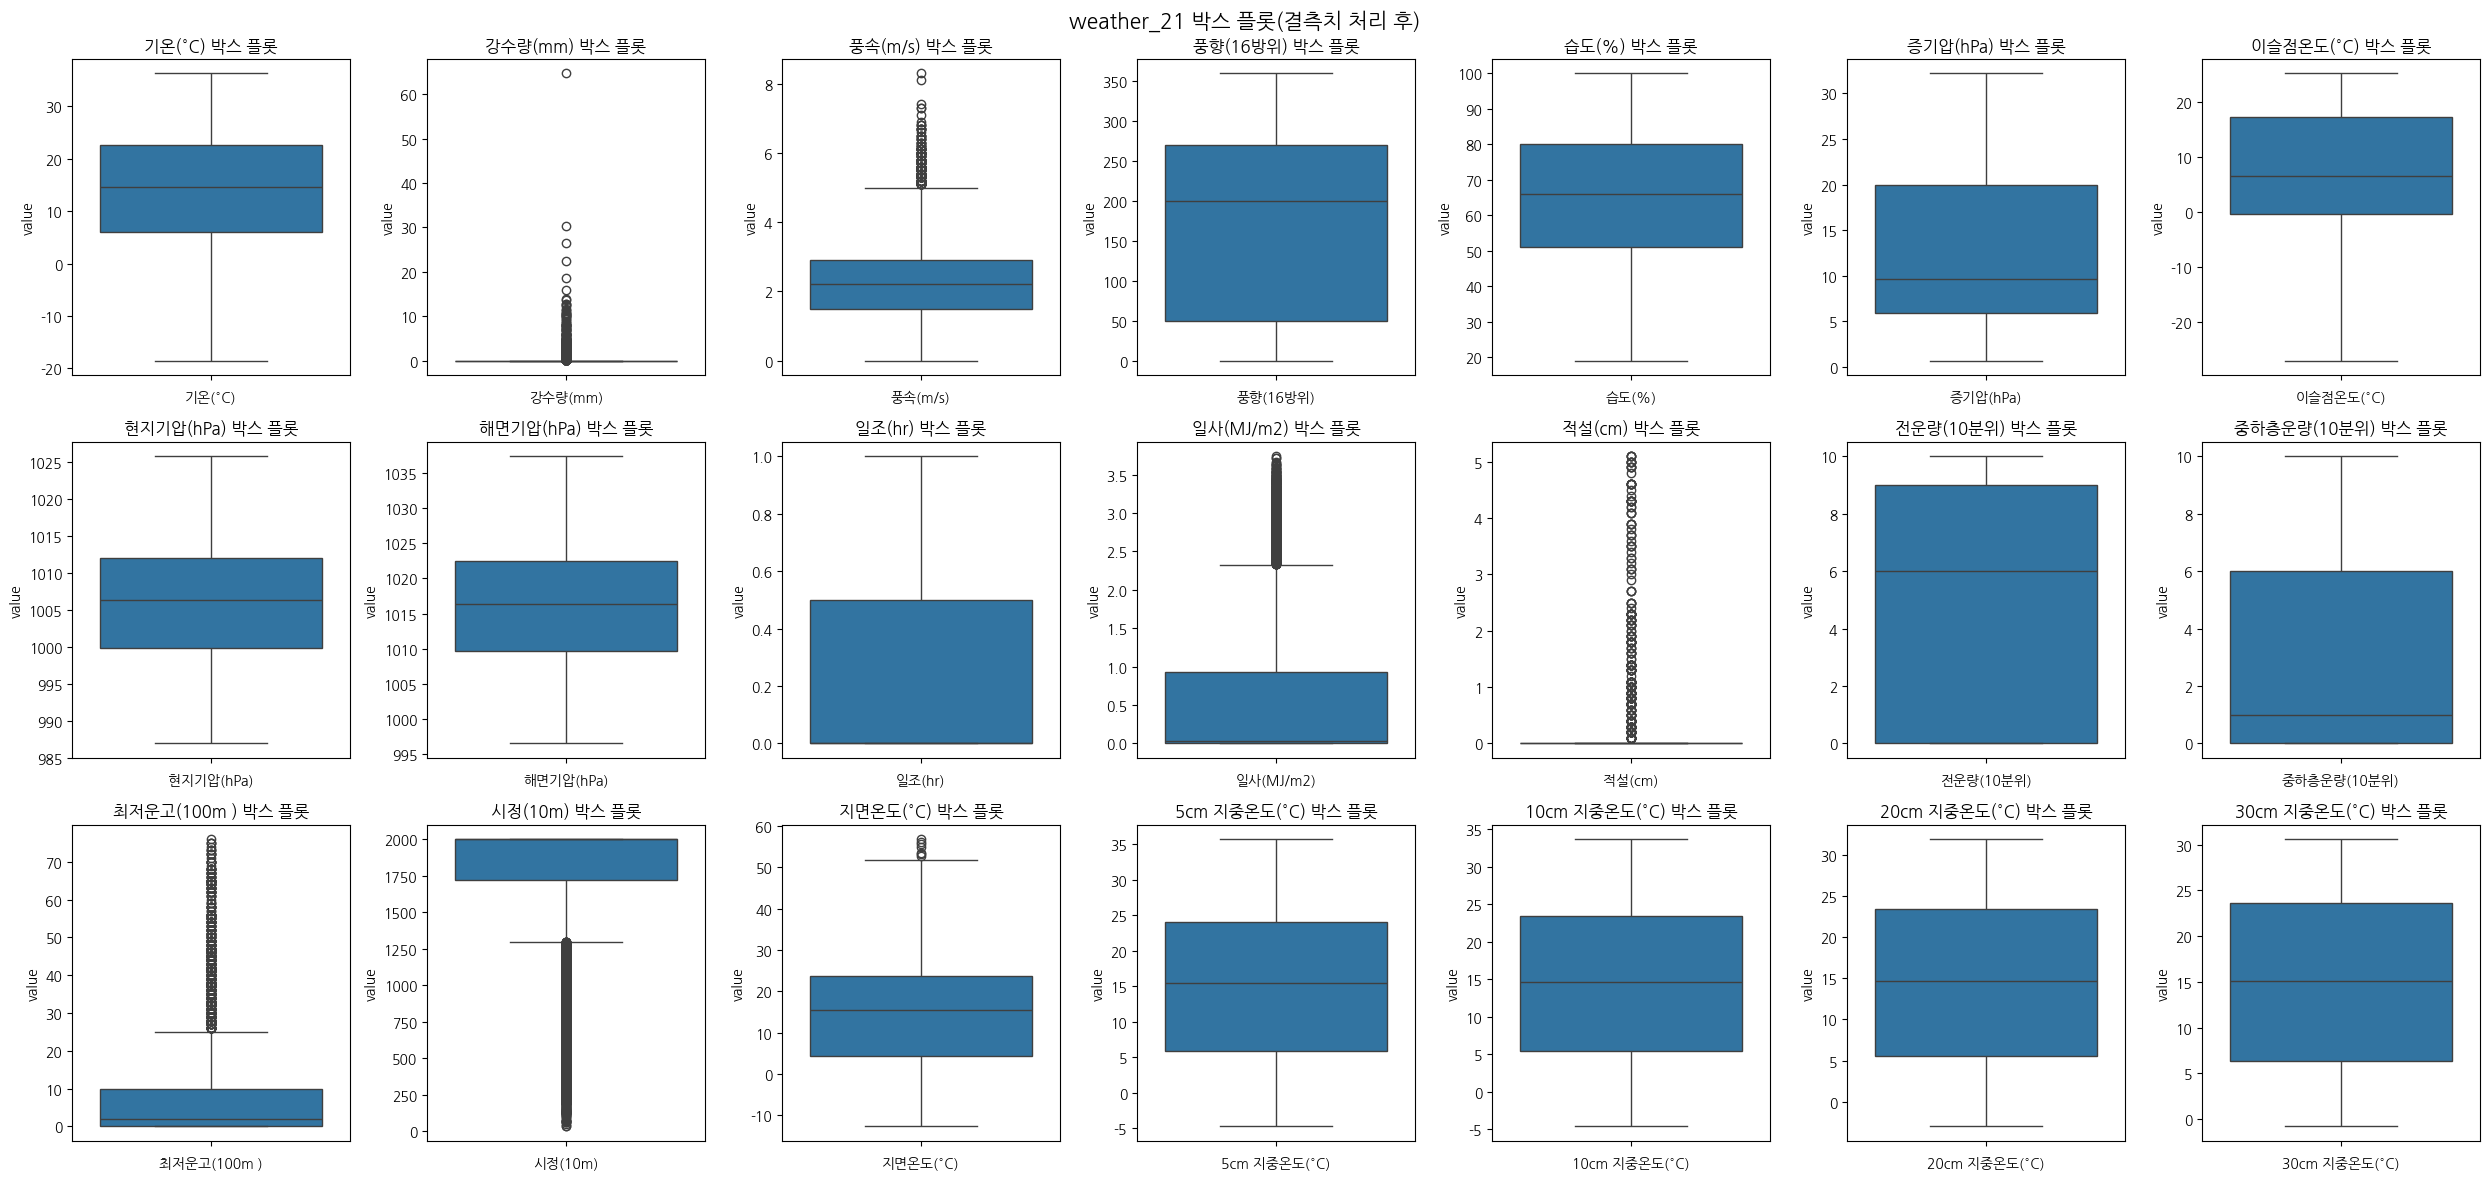

In [77]:
# air_22 박스 플롯
fig, axes = plt.subplots(3, 7, figsize=(25, 12))
cols = ['기온(°C)', '강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
        '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '전운량(10분위)', '중하층운량(10분위)',
        '최저운고(100m )', '시정(10m)', '지면온도(°C)', '5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)']
idx = 0
for r in range(3):
    for c in range(7):
        sns.boxplot(data=weather_21, y=cols[idx], ax=axes[r, c])
        axes[r, c].set_xlabel(cols[idx])
        axes[r, c].set_ylabel('value')
        axes[r, c].set_title(f'{cols[idx]} 박스 플롯')
        idx += 1
fig.suptitle('weather_21 박스 플롯(결측치 처리 후)', fontsize=15)
plt.tight_layout()
plt.show()

In [78]:
temp_list = ['기온(°C)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
                              '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)','전운량(10분위)',
                              '최저운고(100m )', '지면온도(°C)', '5cm 지중온도(°C)', 'PM10'].copy()

In [79]:
# weather_21의 변수간의 상관관계 확인
weather_21_corr = df_21[temp_list].corr()
weather_21_corr

,기온(°C),풍속(m/s),풍향(16방위),습도(%),증기압(hPa),이슬점온도(°C),현지기압(hPa),해면기압(hPa),일조(hr),일사(MJ/m2),전운량(10분위),최저운고(100m ),지면온도(°C),5cm 지중온도(°C),PM10
기온(°C),1.000000,-0.070213,-0.181504,0.145404,0.881615,0.926402,-0.680025,-0.707822,0.121091,0.293800,0.307568,0.209733,0.946657,0.951014,-0.127534
풍속(m/s),-0.070213,1.000000,0.173066,-0.285461,-0.147825,-0.169976,-0.045744,-0.040280,0.251832,0.263515,-0.027250,-0.011026,0.014138,-0.068805,0.011608
풍향(16방위),-0.181504,0.173066,1.000000,-0.200939,-0.189071,-0.231900,0.044013,0.052234,0.072599,0.048850,-0.176922,-0.088554,-0.138163,-0.146669,0.099179
습도(%),0.145404,-0.285461,-0.200939,1.000000,0.450867,0.501853,-0.359807,-0.354960,-0.495825,-0.459769,0.362189,0.003510,0.055417,0.221444,-0.066367
증기압(hPa),0.881615,-0.147825,-0.189071,0.450867,1.000000,0.946841,-0.712216,-0.732223,-0.079263,0.073479,0.356879,0.166807,0.830644,0.912386,-0.205240
이슬점온도(°C),0.926402,-0.169976,-0.231900,0.501853,0.946841,1.000000,-0.726512,-0.748944,-0.089295,0.074238,0.397840,0.189873,0.846028,0.917551,-0.140112
현지기압(hPa),-0.680025,-0.045744,0.044013,-0.359807,-0.712216,-0.726512,1.000000,0.999241,0.076501,-0.077057,-0.358562,-0.118210,-0.646103,-0.703692,0.021823
해면기압(hPa),-0.707822,-0.040280,0.052234,-0.354960,-0.732223,-0.748944,0.999241,1.000000,0.067748,-0.089144,-0.362059,-0.125091,-0.672073,-0.727919,0.027441
일조(hr),0.121091,0.251832,0.072599,-0.495825,-0.079263,-0.089295,0.076501,0.067748,1.000000,0.820351,-0.342247,-0.134158,0.291405,0.016479,0.037855
일사(MJ/m2),0.293800,0.263515,0.048850,-0.459769,0.073479,0.074238,-0.077057,-0.089144,0.820351,1.000000,-0.134607,-0.042131,0.512137,0.177068,0.023471


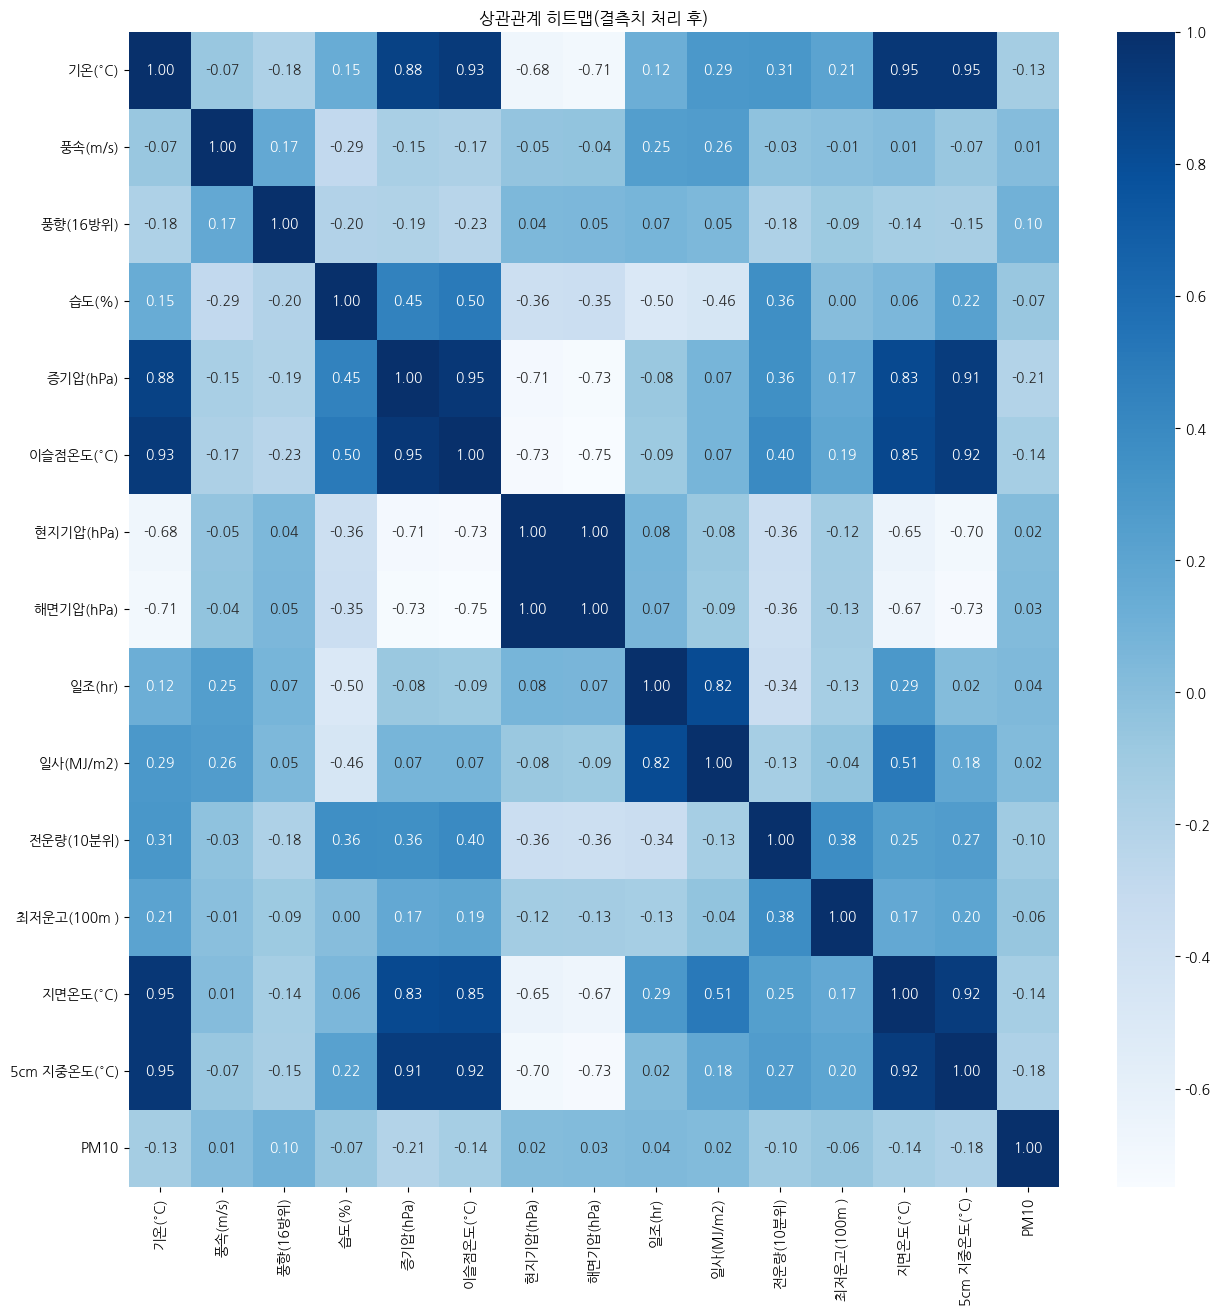

In [80]:
# weather_21의 변수간의 상관관계를 히트맵으로 시각화
plt.figure(figsize=(15, 15))
sns.heatmap(weather_21_corr, annot=True, cmap='Blues', fmt=".2f")
plt.title("상관관계 히트맵(결측치 처리 후)")
plt.show()

### weather_22

In [81]:
weather_22[['기온(°C)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
            '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)','전운량(10분위)',
            '최저운고(100m )', '지면온도(°C)', '5cm 지중온도(°C)']].describe()

,기온(°C),풍속(m/s),풍향(16방위),습도(%),증기압(hPa),이슬점온도(°C),현지기압(hPa),해면기압(hPa),일조(hr),일사(MJ/m2),전운량(10분위),최저운고(100m ),지면온도(°C),5cm 지중온도(°C)
count,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000,2160.000000
mean,1.518148,2.430231,212.856481,57.306481,4.319954,-6.569213,1011.898565,1022.689306,0.270231,0.510718,3.842593,4.284259,2.495093,2.196620
std,6.358060,1.164067,100.383875,17.524800,2.626777,7.366634,5.644250,5.874535,0.419121,0.797644,4.058539,7.990542,7.624066,4.069035
min,-11.300000,0.000000,0.000000,17.000000,1.300000,-19.700000,985.000000,995.000000,0.000000,0.000000,0.000000,0.000000,-10.500000,-2.400000
25%,-3.300000,1.600000,160.000000,45.000000,2.300000,-12.600000,1009.200000,1019.800000,0.000000,0.000000,0.000000,0.000000,-2.800000,-0.300000
50%,1.200000,2.300000,250.000000,55.000000,3.500000,-7.500000,1012.400000,1023.300000,0.000000,0.000000,2.000000,0.000000,0.000000,0.200000
75%,6.100000,3.100000,270.000000,69.000000,5.800000,-0.700000,1016.000000,1026.900000,0.700000,0.840000,8.000000,8.000000,7.000000,4.900000
max,19.400000,7.900000,360.000000,100.000000,14.700000,12.700000,1024.000000,1035.300000,1.000000,3.380000,10.000000,60.000000,31.100000,13.100000


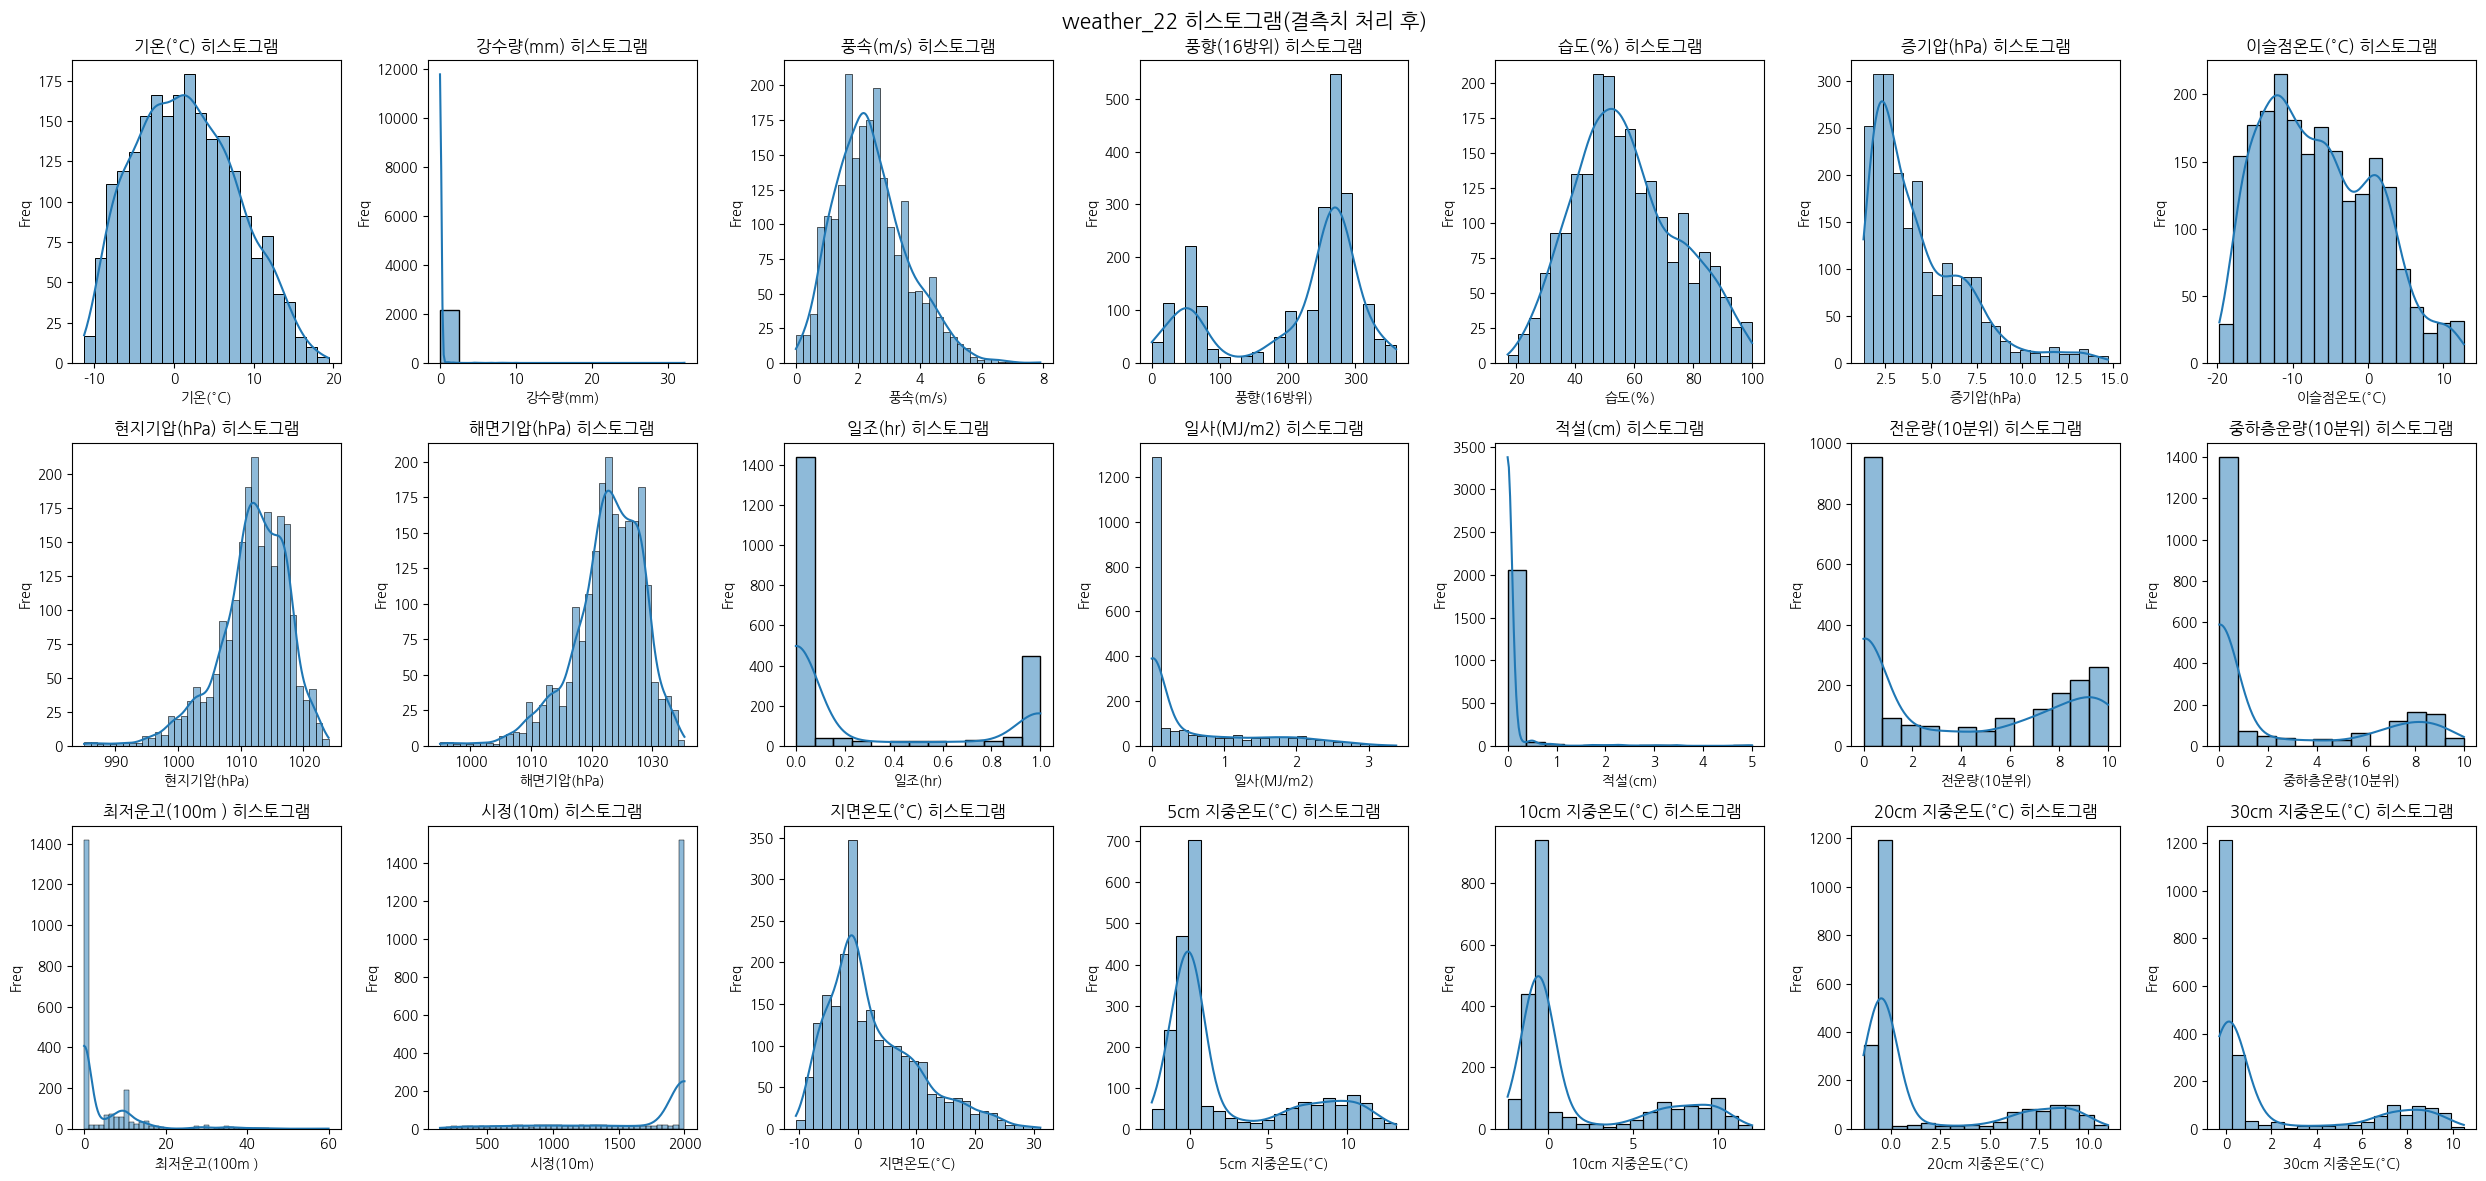

In [82]:
# weather_22 히스토그램
fig, axes = plt.subplots(3, 7, figsize=(25, 12))
cols = ['기온(°C)', '강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
        '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '전운량(10분위)', '중하층운량(10분위)',
        '최저운고(100m )', '시정(10m)', '지면온도(°C)', '5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)']
idx = 0
for r in range(3):
    for c in range(7):
        sns.histplot(data=weather_22, x=cols[idx], kde=True, ax=axes[r, c])
        axes[r, c].set_xlabel(cols[idx])
        axes[r, c].set_ylabel('Freq')
        axes[r, c].set_title(f'{cols[idx]} 히스토그램')
        idx += 1
fig.suptitle('weather_22 히스토그램(결측치 처리 후)', fontsize=15)
plt.tight_layout()
plt.show()

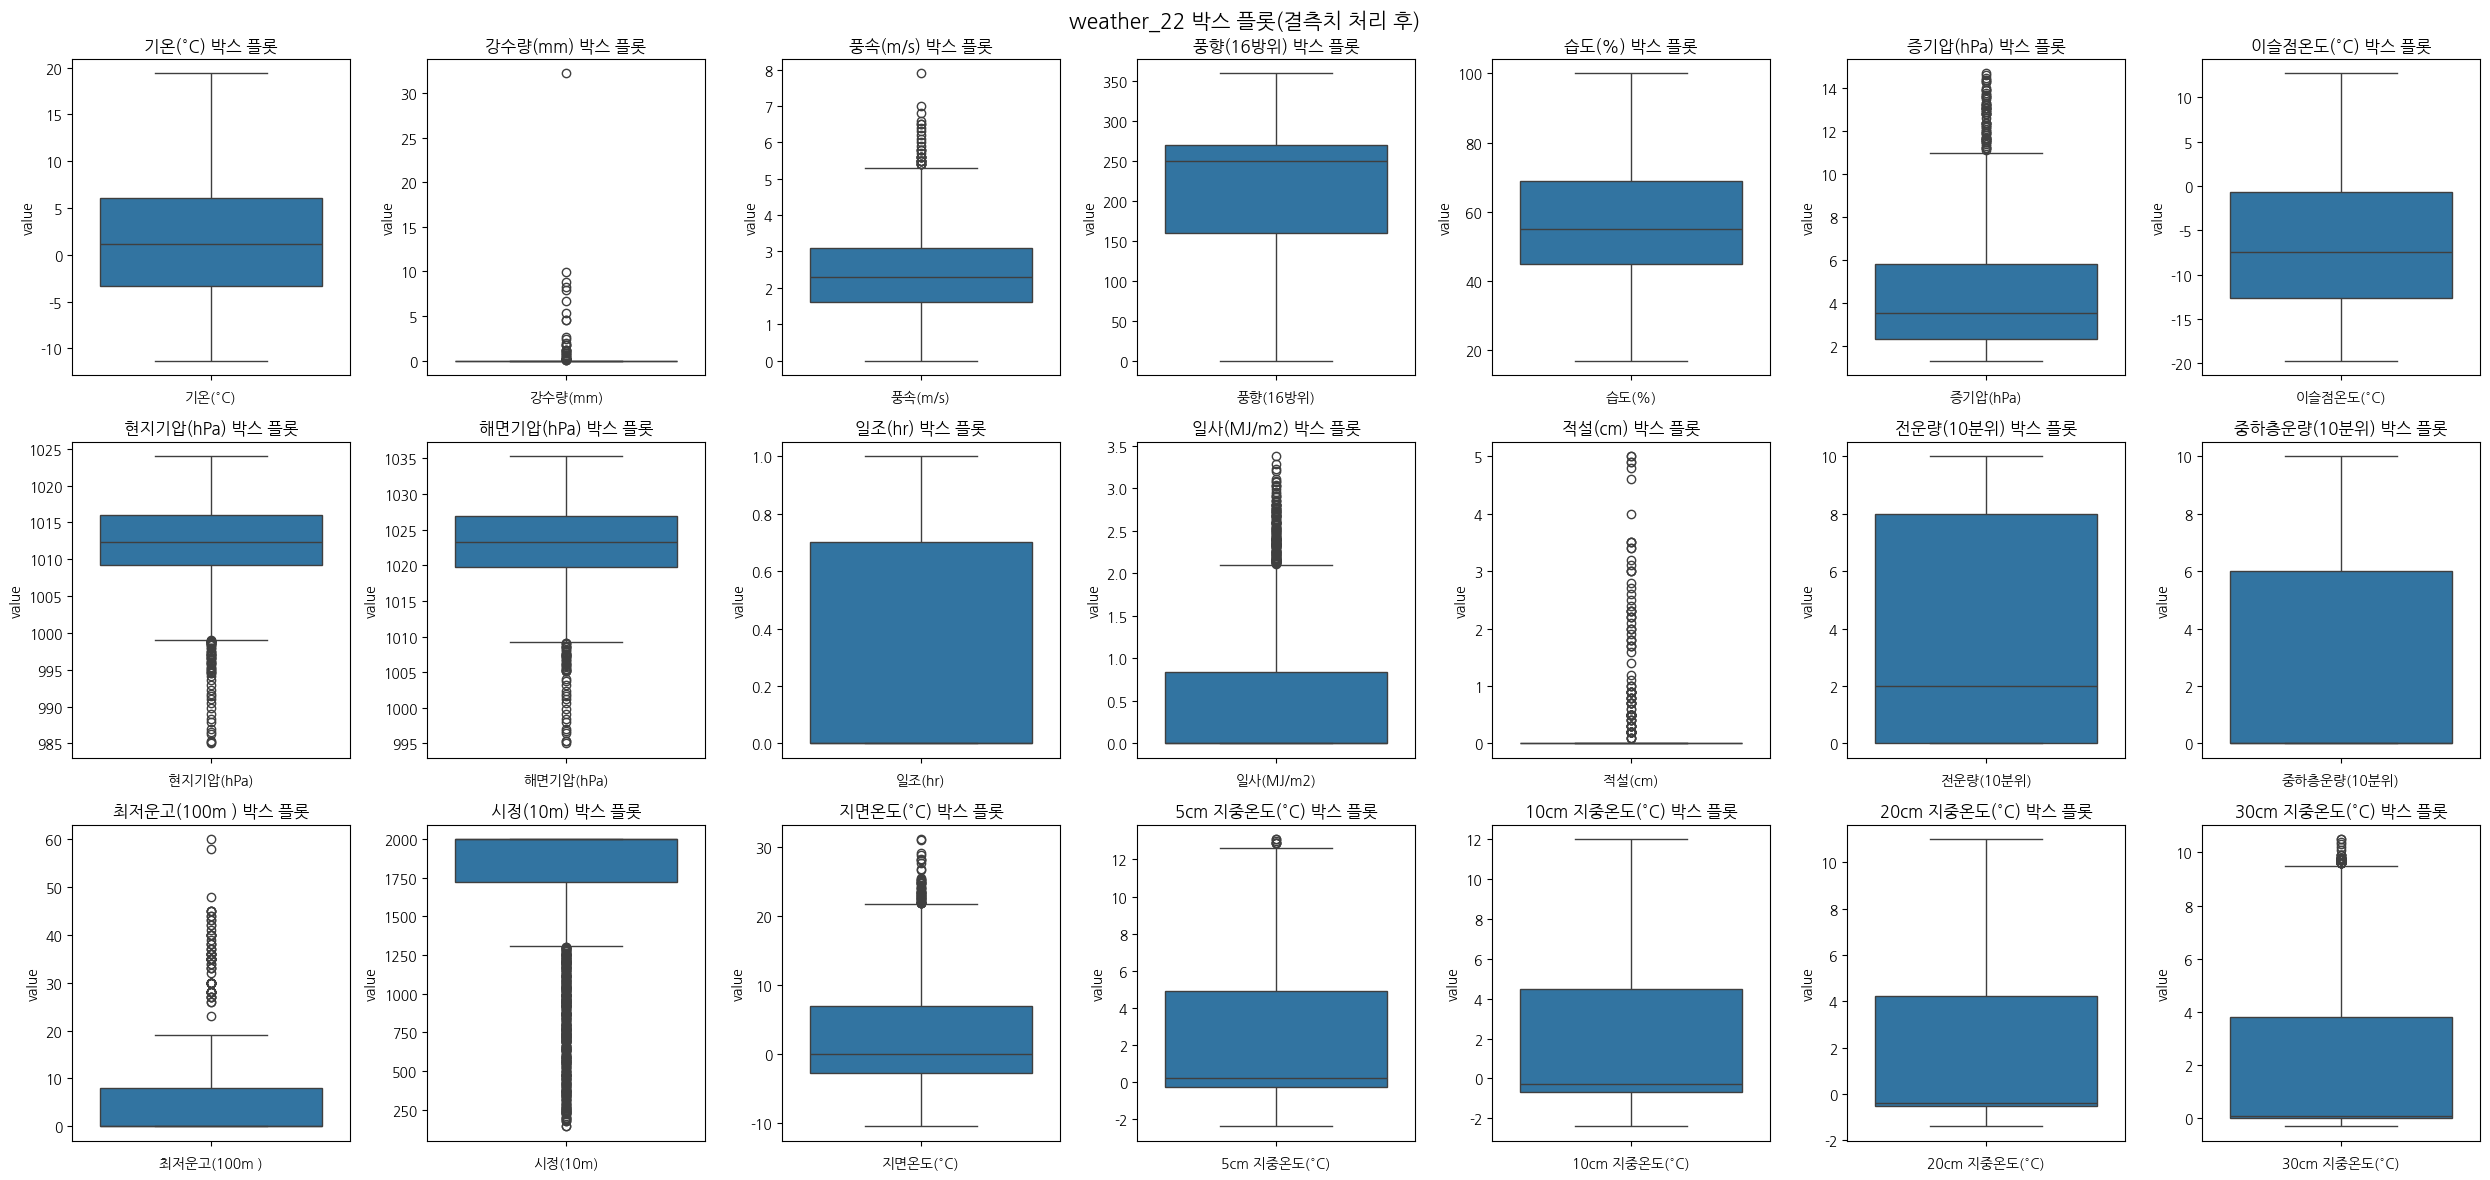

In [83]:
# weather_22 박스 플롯
fig, axes = plt.subplots(3, 7, figsize=(25, 12))
cols = ['기온(°C)', '강수량(mm)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
        '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)', '적설(cm)', '전운량(10분위)', '중하층운량(10분위)',
        '최저운고(100m )', '시정(10m)', '지면온도(°C)', '5cm 지중온도(°C)', '10cm 지중온도(°C)', '20cm 지중온도(°C)', '30cm 지중온도(°C)']
idx = 0
for r in range(3):
    for c in range(7):
        sns.boxplot(data=weather_22, y=cols[idx], ax=axes[r, c])
        axes[r, c].set_xlabel(cols[idx])
        axes[r, c].set_ylabel('value')
        axes[r, c].set_title(f'{cols[idx]} 박스 플롯')
        idx += 1
fig.suptitle('weather_22 박스 플롯(결측치 처리 후)', fontsize=15)
plt.tight_layout()
plt.show()

In [84]:
# weather_22의 변수간의 상관관계 확인
weather_22_corr = weather_22[['기온(°C)', '풍속(m/s)', '풍향(16방위)', '습도(%)', '증기압(hPa)', '이슬점온도(°C)',
                              '현지기압(hPa)', '해면기압(hPa)', '일조(hr)', '일사(MJ/m2)','전운량(10분위)',
                              '최저운고(100m )', '지면온도(°C)', '5cm 지중온도(°C)']].corr()
weather_22_corr

,기온(°C),풍속(m/s),풍향(16방위),습도(%),증기압(hPa),이슬점온도(°C),현지기압(hPa),해면기압(hPa),일조(hr),일사(MJ/m2),전운량(10분위),최저운고(100m ),지면온도(°C),5cm 지중온도(°C)
기온(°C),1.000000,0.138356,-0.140791,0.077777,0.779386,0.817643,-0.622577,-0.649923,0.130274,0.296878,0.450199,0.193686,0.807113,0.790155
풍속(m/s),0.138356,1.000000,0.165936,-0.196221,0.017092,-0.013171,-0.240350,-0.239571,0.277567,0.323466,0.011370,0.053039,0.291831,0.088467
풍향(16방위),-0.140791,0.165936,1.000000,-0.222715,-0.206663,-0.241746,0.135344,0.137701,0.117241,0.082343,-0.226442,-0.134344,-0.035764,-0.118708
습도(%),0.077777,-0.196221,-0.222715,1.000000,0.622775,0.628638,-0.380722,-0.373281,-0.515320,-0.500827,0.330343,0.060615,-0.158087,0.229136
증기압(hPa),0.779386,0.017092,-0.206663,0.622775,1.000000,0.963862,-0.712126,-0.726851,-0.210763,-0.077726,0.528673,0.171422,0.520974,0.770554
이슬점온도(°C),0.817643,-0.013171,-0.241746,0.628638,0.963862,1.000000,-0.697198,-0.714139,-0.214051,-0.076975,0.543310,0.198541,0.520548,0.746860
현지기압(hPa),-0.622577,-0.240350,0.135344,-0.380722,-0.712126,-0.697198,1.000000,0.999358,0.169384,0.051767,-0.443465,-0.175584,-0.417678,-0.615219
해면기압(hPa),-0.649923,-0.239571,0.137701,-0.373281,-0.726851,-0.714139,0.999358,1.000000,0.158598,0.036841,-0.451133,-0.179075,-0.442168,-0.633143
일조(hr),0.130274,0.277567,0.117241,-0.515320,-0.210763,-0.214051,0.169384,0.158598,1.000000,0.843997,-0.302824,-0.148610,0.487312,-0.083524
일사(MJ/m2),0.296878,0.323466,0.082343,-0.500827,-0.077726,-0.076975,0.051767,0.036841,0.843997,1.000000,-0.133637,-0.037413,0.730557,0.056298


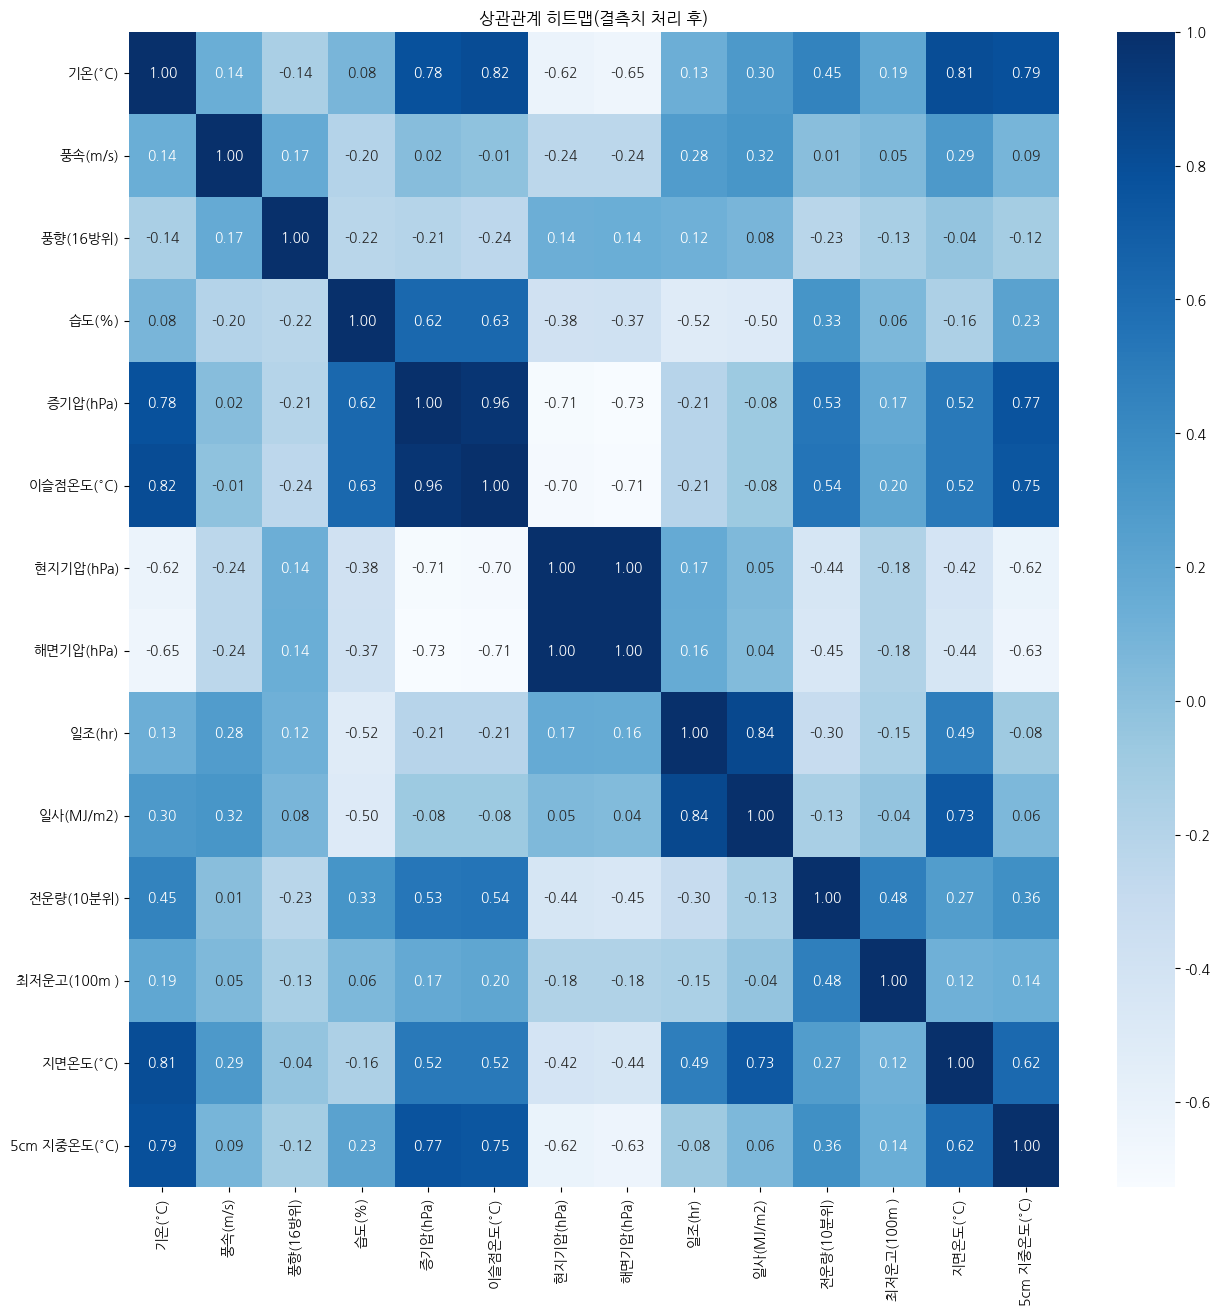

In [85]:
# weather_22의 변수간의 상관관계를 히트맵으로 시각화
plt.figure(figsize=(15, 15))
sns.heatmap(weather_22_corr, annot=True, cmap='Blues', fmt=".2f")
plt.title("상관관계 히트맵(결측치 처리 후)")
plt.show()